# Final EfficientNetV2-S Optimization

EfficientNetV2-S achieved the strongest overall validation results in the controlled comparison with ResNet50, ConvNeXt-Tiny, and DINOv2 ViT-S/14. This notebook performs one predefined final optimization experiment before the selected model is evaluated once on the frozen test subset.

The experiment emphasizes regularization, class-balanced learning, and validation macro F1 rather than maximum training accuracy. The cleaned split from notebook 02 is reused without modification, and no test inference is performed.


## 1. Imports and Reproducibility

The project seed controls Python, NumPy, PyTorch, and training-set shuffling. Deterministic PyTorch behavior is requested where available, with warnings permitted for unsupported deterministic operations.


In [1]:
from pathlib import Path
import os
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
import torch
import torchvision
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import EfficientNet_V2_S_Weights, efficientnet_v2_s
from tqdm.auto import tqdm

RANDOM_SEED = 42


def set_reproducible_seed(seed: int) -> None:
    """Configure deterministic random states for Python, NumPy, and PyTorch."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


set_reproducible_seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CUDA_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if CUDA_AVAILABLE else "Not available"
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
    if CUDA_AVAILABLE
    else 0.0
)

print(f"PyTorch version: {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")
print(f"CUDA available: {CUDA_AVAILABLE}")
print(f"CUDA runtime: {torch.version.cuda}")
print(f"Selected device: {DEVICE}")
print(f"GPU name: {GPU_NAME}")
print(
    f"Total GPU memory: {GPU_MEMORY_GB:.2f} GB"
    if CUDA_AVAILABLE
    else "Total GPU memory: Not available"
)


PyTorch version: 2.13.0+cu132
torchvision version: 0.28.0+cu132
CUDA available: True
CUDA runtime: 13.2
Selected device: cuda
GPU name: NVIDIA GeForce RTX 3060 Laptop GPU
Total GPU memory: 6.00 GB


## 2. Project Paths

The project root is resolved from the current working directory. Processed manifests and the saved EfficientNetV2-S baseline artifacts are required. The optimized checkpoint uses a distinct filename and cannot overwrite the baseline checkpoint.


In [2]:
RAW_RELATIVE_PATH = Path("data/raw/skin-diseases-image-dataset/IMG_CLASSES")


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the raw dataset and processed manifests."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / RAW_RELATIVE_PATH).is_dir()
            and (candidate / "data" / "processed").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing the raw dataset and "
        "data/processed."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / RAW_RELATIVE_PATH
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
PREDICTIONS_DIR = REPORTS_DIR / "predictions"
MODELS_DIR = PROJECT_ROOT / "models"
TORCH_CACHE_DIR = MODELS_DIR / "torch_cache"

for directory in [
    REPORTS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    MODELS_DIR,
    TORCH_CACHE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

torch.hub.set_dir(str(TORCH_CACHE_DIR))

MANIFEST_PATHS = {
    "train": PROCESSED_DIR / "train.csv",
    "validation": PROCESSED_DIR / "validation.csv",
    "test": PROCESSED_DIR / "test.csv",
}
BASELINE_CHECKPOINT_PATH = MODELS_DIR / "efficientnetv2_s_baseline_best.pth"
OPTIMIZED_CHECKPOINT_PATH = MODELS_DIR / "efficientnetv2_s_optimized_best.pth"
CHECKPOINT_PATH = OPTIMIZED_CHECKPOINT_PATH
ARCHITECTURE_COMPARISON_PATH = (
    REPORTS_DIR / "06_architecture_baseline_comparison.csv"
)
BASELINE_METRICS_PATH = REPORTS_DIR / "04_efficientnetv2_validation_metrics.csv"
BASELINE_PER_CLASS_PATH = REPORTS_DIR / "04_efficientnetv2_per_class_metrics.csv"
BASELINE_HISTORY_PATH = REPORTS_DIR / "04_efficientnetv2_training_history.csv"

required_input_paths = [
    *MANIFEST_PATHS.values(),
    BASELINE_CHECKPOINT_PATH,
    ARCHITECTURE_COMPARISON_PATH,
    BASELINE_METRICS_PATH,
    BASELINE_PER_CLASS_PATH,
    BASELINE_HISTORY_PATH,
]
missing_input_paths = [path for path in required_input_paths if not path.is_file()]
if missing_input_paths:
    missing_text = "\n".join(f"  - {path}" for path in missing_input_paths)
    raise FileNotFoundError(
        "Required manifests or baseline artifacts are missing:\n"
        f"{missing_text}"
    )
if BASELINE_CHECKPOINT_PATH == OPTIMIZED_CHECKPOINT_PATH:
    raise ValueError("Baseline and optimized checkpoint paths must remain distinct.")

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset: {RAW_DATA_DIR}")
print(f"Baseline checkpoint: {BASELINE_CHECKPOINT_PATH}")
print(f"Optimized checkpoint: {OPTIMIZED_CHECKPOINT_PATH}")
print(f"Torch cache: {torch.hub.get_dir()}")


Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Raw dataset: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\raw\skin-diseases-image-dataset\IMG_CLASSES
Baseline checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\efficientnetv2_s_baseline_best.pth
Optimized checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\efficientnetv2_s_optimized_best.pth
Torch cache: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache


## 3. Architecture-Selection Context

The saved four-model comparison is read before optimization to verify the stated selection rationale. Values are loaded from the report produced by notebook 06 rather than copied into this notebook.


In [3]:
architecture_baseline_comparison = pd.read_csv(ARCHITECTURE_COMPARISON_PATH)
required_architecture_columns = {
    "architecture",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
}
missing_architecture_columns = required_architecture_columns - set(
    architecture_baseline_comparison.columns
)
if missing_architecture_columns:
    raise ValueError(
        "The architecture comparison is missing columns: "
        f"{sorted(missing_architecture_columns)}"
    )
if architecture_baseline_comparison["architecture"].duplicated().any():
    raise ValueError("The architecture comparison contains duplicate models.")

selected_baseline_architecture = architecture_baseline_comparison.loc[
    architecture_baseline_comparison["macro_f1"].astype(float).idxmax(),
    "architecture",
]
if selected_baseline_architecture != "EfficientNetV2-S":
    raise ValueError(
        "The saved four-model comparison does not identify EfficientNetV2-S "
        "as the strongest macro-F1 baseline. Reconcile model selection before "
        "running final optimization."
    )

display(
    architecture_baseline_comparison.sort_values(
        "macro_f1", ascending=False
    ).style.format(
        {
            "accuracy": "{:.4f}",
            "balanced_accuracy": "{:.4f}",
            "macro_f1": "{:.4f}",
        }
    )
)
print(f"Selected architecture for final optimization: {selected_baseline_architecture}")


,architecture,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,weighted_f1
1,EfficientNetV2-S,0.8892,0.8327,0.8319,0.834926,0.832737,0.890245
2,ConvNeXt-Tiny,0.8846,0.8283,0.8265,0.828763,0.828277,0.885037
3,DINOv2 ViT-S/14,0.8725,0.8211,0.8204,0.824445,0.821123,0.871638
0,ResNet50,0.8533,0.7885,0.7869,0.786947,0.788550,0.853339


Selected architecture for final optimization: EfficientNetV2-S


## 4. Load and Validate Manifests

All three manifests are checked for required fields, class identifiers, class names, retained group assignments, file references, and separation of paths and groups. The split is not regenerated. The test manifest is validated structurally and counted but is never converted into an inference DataLoader.


In [4]:
manifests = {
    split_name: pd.read_csv(path)
    for split_name, path in MANIFEST_PATHS.items()
}
REQUIRED_COLUMNS = {"relative_path", "class_name", "class_id", "group_id"}

for split_name, manifest in manifests.items():
    missing_columns = REQUIRED_COLUMNS - set(manifest.columns)
    if missing_columns:
        raise ValueError(
            f"{MANIFEST_PATHS[split_name].name} is missing columns: "
            f"{sorted(missing_columns)}"
        )
    if manifest[list(REQUIRED_COLUMNS)].isna().any().any():
        raise ValueError(
            f"Required values are missing in {MANIFEST_PATHS[split_name].name}."
        )
    if manifest["relative_path"].duplicated().any():
        raise ValueError(f"Duplicate paths exist within the {split_name} manifest.")
    if "split" in manifest.columns and not manifest["split"].eq(split_name).all():
        raise ValueError(
            f"The split column is inconsistent in "
            f"{MANIFEST_PATHS[split_name].name}."
        )
    numeric_class_ids = pd.to_numeric(manifest["class_id"], errors="coerce")
    if numeric_class_ids.isna().any() or not np.equal(
        numeric_class_ids, numeric_class_ids.astype(int)
    ).all():
        raise ValueError(f"Non-integer class IDs exist in the {split_name} manifest.")

all_paths = pd.concat(
    [
        manifest[["relative_path"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
if all_paths["relative_path"].duplicated().any():
    duplicated_paths = all_paths.loc[
        all_paths["relative_path"].duplicated(keep=False), "relative_path"
    ]
    raise ValueError(
        f"{duplicated_paths.nunique():,} image path(s) occur in more than one split."
    )

all_groups = pd.concat(
    [
        manifest[["group_id"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
group_split_counts = all_groups.groupby("group_id")["source_split"].nunique()
if (group_split_counts > 1).any():
    raise ValueError(
        f"{int((group_split_counts > 1).sum()):,} group ID(s) occur across splits."
    )

missing_images = [
    relative_path
    for relative_path in all_paths["relative_path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images):,} manifest image paths do not exist on disk."
    )

split_summary = pd.DataFrame(
    {
        "split": list(manifests),
        "images": [len(manifests[name]) for name in manifests],
    }
)
split_summary["percentage"] = (
    100 * split_summary["images"] / split_summary["images"].sum()
)
display(split_summary)

class_distribution = pd.concat(
    [
        manifest.groupby(["class_id", "class_name"])
        .size()
        .rename("images")
        .reset_index()
        .assign(split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
display(class_distribution.sort_values(["class_id", "split"]))

print(f"Training images: {len(manifests['train']):,}")
print(f"Validation images: {len(manifests['validation']):,}")
print(f"Frozen test images (structural validation only): {len(manifests['test']):,}")
print(f"Unique paths across all splits: {all_paths['relative_path'].nunique():,}")
print(f"Unique group IDs across all splits: {all_groups['group_id'].nunique():,}")


,split,images,percentage
0,train,18491,70.009844
1,validation,3961,14.996971
2,test,3960,14.993185


,class_id,class_name,images,split
20,0,Eczema,230,test
0,0,Eczema,1068,train
10,0,Eczema,228,validation
21,1,Melanoma,470,test
1,1,Melanoma,2195,train
11,1,Melanoma,471,validation
22,2,Atopic Dermatitis,174,test
2,2,Atopic Dermatitis,804,train
12,2,Atopic Dermatitis,171,validation
23,3,Basal Cell Carcinoma (BCC),496,test


Training images: 18,491
Validation images: 3,961
Frozen test images (structural validation only): 3,960
Unique paths across all splits: 26,412
Unique group IDs across all splits: 26,293


## 5. Class Mapping

Class identifiers and names are derived directly from the manifests. The mapping must be contiguous, one-to-one, and identical in every split.


In [5]:
mapping_frames = []
for split_name, manifest in manifests.items():
    split_mapping = manifest[["class_id", "class_name"]].drop_duplicates().copy()
    split_mapping["class_id"] = split_mapping["class_id"].astype(int)
    if (
        split_mapping["class_id"].duplicated().any()
        or split_mapping["class_name"].duplicated().any()
    ):
        raise ValueError(
            f"The class mapping is not one-to-one in the {split_name} manifest."
        )
    mapping_frames.append(split_mapping.assign(split=split_name))

mapping_check = pd.concat(mapping_frames, ignore_index=True)
class_mapping_table = (
    mapping_check[["class_id", "class_name"]]
    .drop_duplicates()
    .sort_values("class_id", ignore_index=True)
)
if mapping_check.groupby("split").size().nunique() != 1:
    raise ValueError("The manifests do not contain the same number of classes.")
if class_mapping_table["class_id"].tolist() != list(range(len(class_mapping_table))):
    raise ValueError("Class IDs are not contiguous from zero.")
for split_name, split_mapping in mapping_check.groupby("split"):
    observed = (
        split_mapping[["class_id", "class_name"]]
        .sort_values("class_id")
        .reset_index(drop=True)
    )
    if not observed.equals(class_mapping_table):
        raise ValueError(f"Class mapping differs in the {split_name} manifest.")

CLASS_ID_TO_NAME = dict(
    zip(class_mapping_table["class_id"], class_mapping_table["class_name"])
)
NUM_CLASSES = len(CLASS_ID_TO_NAME)
display(class_mapping_table)
print(f"Number of classes: {NUM_CLASSES}")


,class_id,class_name
0,0,Eczema
1,1,Melanoma
2,2,Atopic Dermatitis
3,3,Basal Cell Carcinoma (BCC)
4,4,Melanocytic Nevi (NV)
5,5,Benign Keratosis-like Lesions (BKL)
6,6,Psoriasis / Lichen Planus / Related Diseases
7,7,Seborrheic Keratoses / Other Benign Tumors
8,8,Tinea / Ringworm / Candidiasis / Other Fungal ...
9,9,Warts / Molluscum / Other Viral Infections


Number of classes: 10


## 6. Training Distribution and Mild Class Weights

Class weights use only training-subset frequencies. For class (c), the raw value is

\[
w_c^{raw} = \sqrt{\frac{N}{K n_c}},
\]

where (N) is the number of training images, (K) is the number of classes, and (n_c) is the class count. Raw values are normalized to mean 1 and clipped to [0.75, 1.50]. This conservative transformation increases attention to smaller classes without allowing inverse-frequency weights to dominate optimization.


In [6]:
training_distribution = (
    manifests["train"]
    .groupby(["class_id", "class_name"])
    .size()
    .rename("training_images")
    .reset_index()
    .sort_values("class_id", ignore_index=True)
)
if training_distribution["class_id"].tolist() != list(CLASS_ID_TO_NAME):
    raise ValueError("Training distribution does not cover the active class mapping.")
training_distribution["training_percentage"] = (
    100
    * training_distribution["training_images"]
    / training_distribution["training_images"].sum()
)
display(
    training_distribution.style.format(
        {"training_images": "{:,}", "training_percentage": "{:.2f}%"}
    )
)

total_training_images = int(training_distribution["training_images"].sum())
raw_class_weights = np.sqrt(
    total_training_images
    / (NUM_CLASSES * training_distribution["training_images"].to_numpy())
)
mean_normalized_weights = raw_class_weights / raw_class_weights.mean()
final_class_weights = np.clip(mean_normalized_weights, 0.75, 1.50)

class_weight_table = training_distribution[
    ["class_id", "class_name", "training_images"]
].copy()
class_weight_table["raw_weight"] = raw_class_weights
class_weight_table["final_weight"] = final_class_weights
class_weight_table.to_csv(
    REPORTS_DIR / "07_class_weights.csv", index=False, encoding="utf-8"
)
display(
    class_weight_table.style.format(
        {
            "training_images": "{:,}",
            "raw_weight": "{:.4f}",
            "final_weight": "{:.4f}",
        }
    )
)

class_weights = torch.tensor(
    final_class_weights, dtype=torch.float32, device=DEVICE
)
print(f"Mean weight before clipping: {mean_normalized_weights.mean():.4f}")
print(
    f"Final weight range: {final_class_weights.min():.4f} to "
    f"{final_class_weights.max():.4f}"
)


,class_id,class_name,training_images,training_percentage
0,0,Eczema,"1,068",5.78%
1,1,Melanoma,"2,195",11.87%
2,2,Atopic Dermatitis,804,4.35%
3,3,Basal Cell Carcinoma (BCC),"2,323",12.56%
4,4,Melanocytic Nevi (NV),"5,577",30.16%
5,5,Benign Keratosis-like Lesions (BKL),"1,446",7.82%
6,6,Psoriasis / Lichen Planus / Related Diseases,"1,365",7.38%
7,7,Seborrheic Keratoses / Other Benign Tumors,"1,278",6.91%
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,"1,143",6.18%
9,9,Warts / Molluscum / Other Viral Infections,"1,292",6.99%


,class_id,class_name,training_images,raw_weight,final_weight
0,0,Eczema,"1,068",1.3158,1.1765
1,1,Melanoma,"2,195",0.9178,0.8207
2,2,Atopic Dermatitis,804,1.5165,1.3560
3,3,Basal Cell Carcinoma (BCC),"2,323",0.8922,0.7977
4,4,Melanocytic Nevi (NV),"5,577",0.5758,0.7500
5,5,Benign Keratosis-like Lesions (BKL),"1,446",1.1308,1.0111
6,6,Psoriasis / Lichen Planus / Related Diseases,"1,365",1.1639,1.0407
7,7,Seborrheic Keratoses / Other Benign Tumors,"1,278",1.2029,1.0755
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,"1,143",1.2719,1.1373
9,9,Warts / Molluscum / Other Viral Infections,"1,292",1.1963,1.0697


Mean weight before clipping: 1.0000
Final weight range: 0.7500 to 1.3560


## 7. EfficientNetV2-S Input Processing

The optimized experiment retains the 384 x 384 EfficientNetV2-S baseline resolution and the normalization defined by the default pretrained weights. Training augmentation is slightly stronger than in notebook 04 but excludes vertical flips, strong color changes, blur, perspective distortion, MixUp, CutMix, and Random Erasing. Validation preprocessing is deterministic and identical in methodology to the baseline.


In [7]:
IMAGE_SIZE = 384
PRETRAINED_WEIGHTS = EfficientNet_V2_S_Weights.DEFAULT
validation_transform = PRETRAINED_WEIGHTS.transforms()
IMAGENET_MEAN = list(validation_transform.mean)
IMAGENET_STD = list(validation_transform.std)

if tuple(validation_transform.crop_size) not in {
    (IMAGE_SIZE,),
    (IMAGE_SIZE, IMAGE_SIZE),
}:
    raise ValueError(
        "The pretrained EfficientNetV2-S validation transform does not produce "
        f"{IMAGE_SIZE} x {IMAGE_SIZE} inputs."
    )

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.75, 1.00),
            ratio=(0.85, 1.15),
            interpolation=validation_transform.interpolation,
            antialias=True,
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(
            degrees=15,
            interpolation=validation_transform.interpolation,
        ),
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.15,
            hue=0.03,
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

print(f"Pretrained weights: {PRETRAINED_WEIGHTS.name}")
print(f"Image size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Validation resize size: {validation_transform.resize_size}")
print(f"Normalization mean: {IMAGENET_MEAN}")
print(f"Normalization standard deviation: {IMAGENET_STD}")


Pretrained weights: IMAGENET1K_V1
Image size: 384 x 384
Validation resize size: [384]
Normalization mean: [0.485, 0.456, 0.406]
Normalization standard deviation: [0.229, 0.224, 0.225]


## 8. Dataset and DataLoaders

Images are opened from each manifest's `relative_path`, corrected for EXIF orientation, converted to RGB, and transformed in memory. Labels come exclusively from the manifest.

`BATCH_SIZE = 8` is fixed for 384 x 384 inputs on the available 6 GB GPU. Worker processes are disabled for reliable Windows/Jupyter execution, and no automatic batch-size search is performed.


In [8]:
class SkinDiseaseDataset(Dataset):
    """Load images and labels directly from a processed manifest."""

    def __init__(self, manifest: pd.DataFrame, project_root: Path, transform=None):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.manifest)

    def __getitem__(self, index: int):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["relative_path"]
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, int(row["class_id"]), row["relative_path"]


train_dataset = SkinDiseaseDataset(
    manifests["train"], PROJECT_ROOT, transform=train_transform
)
validation_dataset = SkinDiseaseDataset(
    manifests["validation"], PROJECT_ROOT, transform=validation_transform
)

BATCH_SIZE = 8
NUM_WORKERS = 0  # Reliable for Windows and interactive Jupyter execution.
PIN_MEMORY = CUDA_AVAILABLE

train_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=train_generator,
    persistent_workers=NUM_WORKERS > 0,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
)

print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print(f"Pinned memory: {PIN_MEMORY}")


Training batches: 2,312
Validation batches: 496
Batch size: 8
DataLoader workers: 0
Pinned memory: True


## 9. Data Sanity Check

A small augmented training batch is converted back to display space. This check verifies label display, sensible crops, and preservation of visually interpretable content. It does not constitute clinical diagnosis.


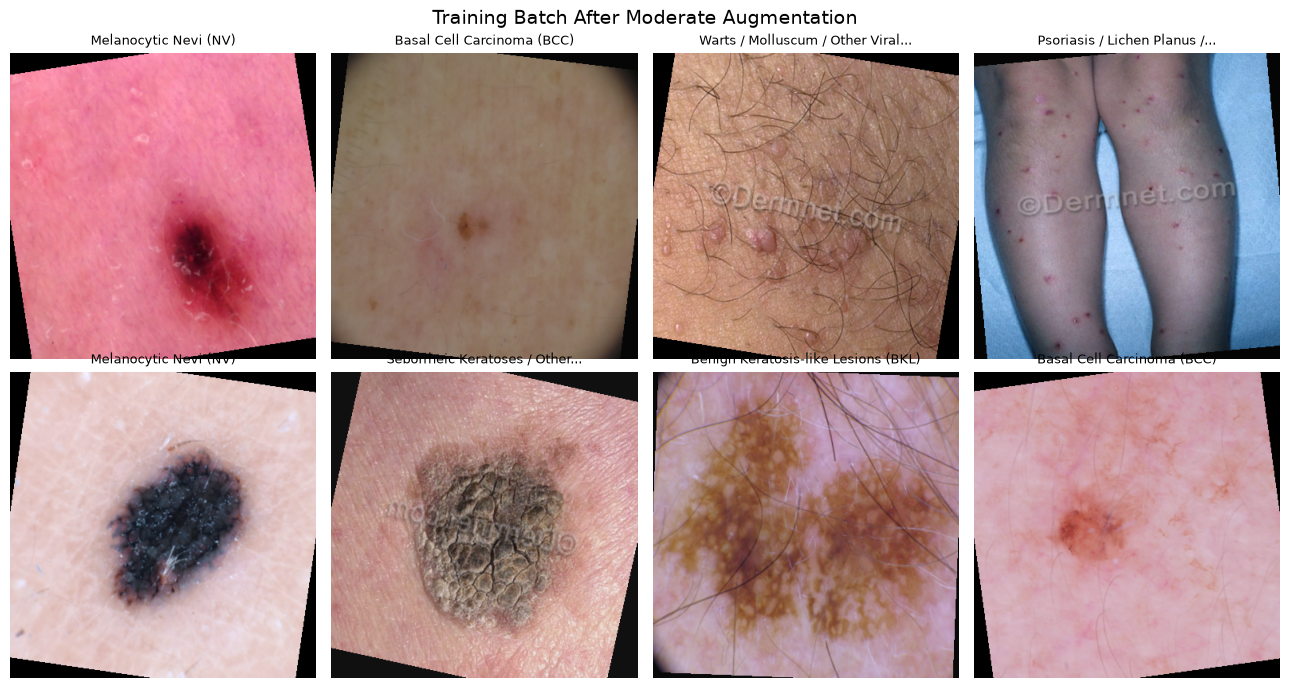

In [9]:
sample_images, sample_labels, _ = next(iter(train_loader))
train_generator.manual_seed(RANDOM_SEED)

mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)
display_count = min(8, len(sample_images))

fig, axes = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
for axis, image_tensor, label in zip(
    axes.flat, sample_images[:display_count], sample_labels[:display_count]
):
    image_for_display = (image_tensor.cpu() * std_tensor + mean_tensor).clamp(0, 1)
    axis.imshow(image_for_display.permute(1, 2, 0).numpy())
    axis.set_title(
        textwrap.shorten(
            CLASS_ID_TO_NAME[int(label)], width=35, placeholder="..."
        ),
        fontsize=9,
    )
    axis.axis("off")
for axis in axes.flat[display_count:]:
    axis.axis("off")
fig.suptitle("Training Batch After Moderate Augmentation", fontsize=14)
fig.tight_layout()
plt.show()


## 10. Optimized Model, Loss, and Training Configuration

The pretrained EfficientNetV2-S classifier dropout is set to 0.30 and its final linear layer is replaced with `NUM_CLASSES` outputs. The loss combines the training-derived mild class weights with label smoothing of 0.05. Weighting addresses unequal training frequency, while label smoothing discourages excessive confidence and may improve generalization.

Stage 1 trains the classifier at (5 \times 10^{-4}). Stage 2 unfreezes the full network and uses (3 \times 10^{-5}) for the feature backbone and (1 \times 10^{-4}) for the classifier. `ReduceLROnPlateau` receives group-specific minimum learning rates of (10^{-6}) and (3 \times 10^{-6}), respectively.


In [10]:
model = efficientnet_v2_s(weights=PRETRAINED_WEIGHTS)
FINAL_DROPOUT = 0.30
LABEL_SMOOTHING = 0.05

dropout_layers = [
    module for module in model.classifier if isinstance(module, nn.Dropout)
]
if len(dropout_layers) != 1:
    raise ValueError(
        "Expected exactly one dropout layer in the EfficientNetV2-S classifier."
    )
dropout_layers[0].p = FINAL_DROPOUT
classifier_input_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(classifier_input_features, NUM_CLASSES)
model = model.to(DEVICE)

WARMUP_EPOCHS = 3
FINE_TUNE_MAX_EPOCHS = 20
WARMUP_LEARNING_RATE = 5e-4
BACKBONE_LEARNING_RATE = 3e-5
CLASSIFIER_FINE_TUNE_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 2e-4
EARLY_STOPPING_PATIENCE = 6
CHECKPOINT_CRITERION = "validation_macro_f1"
SCHEDULER_MIN_LRS = [1e-6, 3e-6]

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING,
)

TRAINING_CONFIGURATION = {
    "random_seed": RANDOM_SEED,
    "architecture": "EfficientNetV2-S Optimized",
    "pretrained_weights": PRETRAINED_WEIGHTS.name,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "loss": "Weighted CrossEntropyLoss with label smoothing",
    "class_weighting": "Square-root inverse frequency, mean-normalized, clipped [0.75, 1.50]",
    "label_smoothing": LABEL_SMOOTHING,
    "classifier_dropout": FINAL_DROPOUT,
    "optimizer": "AdamW",
    "warmup_learning_rate": WARMUP_LEARNING_RATE,
    "backbone_learning_rate": BACKBONE_LEARNING_RATE,
    "classifier_fine_tune_learning_rate": CLASSIFIER_FINE_TUNE_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_epochs": WARMUP_EPOCHS,
    "fine_tune_max_epochs": FINE_TUNE_MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "checkpoint_criterion": CHECKPOINT_CRITERION,
    "scheduler_min_lrs": SCHEDULER_MIN_LRS,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": GPU_NAME,
}

total_parameters = sum(parameter.numel() for parameter in model.parameters())
initial_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print("Architecture: EfficientNetV2-S Optimized")
print(f"Pretrained weights: {PRETRAINED_WEIGHTS.name}")
print(f"Total parameters: {total_parameters:,}")
print(f"Initially trainable parameters: {initial_trainable_parameters:,}")
print(f"Classifier dropout: {dropout_layers[0].p:.2f}")
print(f"Output classes: {NUM_CLASSES}")


Architecture: EfficientNetV2-S Optimized
Pretrained weights: IMAGENET1K_V1
Total parameters: 20,190,298
Initially trainable parameters: 20,190,298
Classifier dropout: 0.30
Output classes: 10


## 11. Training, Validation, and Checkpoint Functions

Training loss and accuracy are sample-weighted. Validation uses inference mode, and all scikit-learn metric inputs are CPU arrays. Automatic mixed precision is enabled only on CUDA. A CUDA memory error is reported explicitly and never triggers a silent CPU fallback.


In [11]:
AMP_ENABLED = DEVICE.type == "cuda"
HISTORY_PATH = REPORTS_DIR / "07_efficientnetv2_optimized_training_history.csv"


def calculate_classification_metrics(targets, predictions) -> dict:
    """Calculate checkpoint-selection metrics from CPU arrays."""
    return {
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets, predictions, average="macro", zero_division=0
        ),
    }


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    freeze_backbone: bool,
):
    """Train for one epoch and return sample-weighted loss and accuracy."""
    model.train()
    if freeze_backbone:
        # Prevent frozen BatchNorm statistics from changing during warm-up.
        model.features.eval()

    running_loss = 0.0
    correct_predictions = 0
    sample_count = 0
    progress = tqdm(loader, desc="Training", unit="batch", leave=False)

    for images, labels, _ in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory with the predefined batch size of 8. "
                "Stop the run, restart the kernel, and free other GPU memory. "
                "The notebook will not fall back to CPU or change batch size "
                "automatically."
            ) from error

        current_batch_size = labels.size(0)
        running_loss += loss.detach().item() * current_batch_size
        correct_predictions += (
            logits.detach().argmax(dim=1) == labels
        ).sum().item()
        sample_count += current_batch_size
        progress.set_postfix(
            loss=f"{running_loss / sample_count:.4f}",
            accuracy=f"{correct_predictions / sample_count:.3f}",
        )

    return {
        "loss": running_loss / sample_count,
        "accuracy": correct_predictions / sample_count,
    }


@torch.inference_mode()
def evaluate_model(model, loader, criterion, device, description="Validation"):
    """Return validation metrics and CPU prediction information."""
    model.eval()
    running_loss = 0.0
    sample_count = 0
    targets = []
    predictions = []
    confidences = []
    probability_batches = []
    relative_paths = []

    progress = tqdm(loader, desc=description, unit="batch", leave=False)
    for images, labels, paths in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory during validation. Stop the run, restart "
                "the kernel, and free other GPU memory before retrying."
            ) from error

        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predicted = probabilities.max(dim=1)
        current_batch_size = labels.size(0)
        running_loss += loss.item() * current_batch_size
        sample_count += current_batch_size
        targets.extend(labels.cpu().numpy().tolist())
        predictions.extend(predicted.cpu().numpy().tolist())
        confidences.extend(confidence.cpu().numpy().tolist())
        probability_batches.append(probabilities.cpu().numpy())
        relative_paths.extend(paths)

    targets = np.asarray(targets, dtype=np.int64)
    predictions = np.asarray(predictions, dtype=np.int64)
    confidences = np.asarray(confidences, dtype=np.float32)
    probabilities = np.concatenate(probability_batches, axis=0)
    metric_values = calculate_classification_metrics(targets, predictions)

    return {
        "loss": running_loss / sample_count,
        **metric_values,
        "targets": targets,
        "predictions": predictions,
        "confidences": confidences,
        "probabilities": probabilities,
        "relative_paths": relative_paths,
    }


def save_best_checkpoint(
    path: Path,
    model,
    epoch: int,
    stage: str,
    validation_metrics: dict,
) -> None:
    """Save the macro-F1-selected optimized model and experiment metadata."""
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "architecture": "EfficientNetV2-S Optimized",
            "class_mapping": CLASS_ID_TO_NAME,
            "class_weights": class_weights.detach().cpu().tolist(),
            "label_smoothing": LABEL_SMOOTHING,
            "dropout": FINAL_DROPOUT,
            "best_validation_macro_f1": validation_metrics["macro_f1"],
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_balanced_accuracy": validation_metrics[
                "balanced_accuracy"
            ],
            "epoch": epoch,
            "stage": stage,
            "image_size": IMAGE_SIZE,
            "training_configuration": TRAINING_CONFIGURATION,
        },
        path,
    )


def load_model_checkpoint(path: Path, model, device):
    """Restore parameters from the optimized EfficientNetV2-S checkpoint."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()
    return checkpoint


def record_epoch(
    history,
    epoch: int,
    stage: str,
    training_metrics: dict,
    validation_metrics: dict,
    backbone_learning_rate: float,
    classifier_learning_rate: float,
) -> None:
    """Append and persist one epoch using the standardized history schema."""
    history.append(
        {
            "epoch": epoch,
            "stage": stage,
            "train_loss": training_metrics["loss"],
            "train_accuracy": training_metrics["accuracy"],
            "val_loss": validation_metrics["loss"],
            "val_accuracy": validation_metrics["accuracy"],
            "val_balanced_accuracy": validation_metrics["balanced_accuracy"],
            "val_macro_f1": validation_metrics["macro_f1"],
            "learning_rate": classifier_learning_rate,
            "backbone_learning_rate": backbone_learning_rate,
            "classifier_learning_rate": classifier_learning_rate,
        }
    )
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False, encoding="utf-8")


## 12. Two-Stage Final Training

### Stage 1 - Classifier Warm-Up

The feature backbone is frozen and its BatchNorm layers remain in evaluation mode. The classifier alone is trained for three epochs using the final weighted and label-smoothed loss.

### Stage 2 - Full Fine-Tuning

The full network is unfrozen. Separate AdamW parameter groups retain a lower learning rate for pretrained features than for the classifier. The scheduler monitors validation macro F1 with group-specific nonzero minimum learning rates. Early stopping uses six consecutive epochs without an improvement over the best checkpoint observed in either stage.


In [12]:
history = []
best_validation_macro_f1 = -np.inf
best_epoch = None
best_stage = None
global_epoch = 0

# Stage 1: classifier warm-up.
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

warmup_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 1 trainable parameters: {warmup_trainable_parameters:,}")

warmup_optimizer = AdamW(
    model.classifier.parameters(),
    lr=WARMUP_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
warmup_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

for stage_epoch in range(1, WARMUP_EPOCHS + 1):
    global_epoch += 1
    print(
        f"Stage 1/2 - classifier warm-up epoch "
        f"{stage_epoch}/{WARMUP_EPOCHS}"
    )
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        warmup_optimizer,
        warmup_scaler,
        DEVICE,
        freeze_backbone=True,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    classifier_lr = warmup_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "classifier_warmup",
        training_metrics,
        validation_metrics,
        backbone_learning_rate=0.0,
        classifier_learning_rate=classifier_lr,
    )

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "classifier_warmup"
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )
        improvement_note = "checkpoint updated"
    else:
        improvement_note = "checkpoint unchanged"

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val balanced accuracy={validation_metrics['balanced_accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}; "
        f"{improvement_note}"
    )

# Stage 2: full-network fine-tuning with discriminative learning rates.
for parameter in model.parameters():
    parameter.requires_grad = True

fine_tune_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 2 trainable parameters: {fine_tune_trainable_parameters:,}")

fine_tune_optimizer = AdamW(
    [
        {
            "params": model.features.parameters(),
            "lr": BACKBONE_LEARNING_RATE,
            "name": "backbone",
        },
        {
            "params": model.classifier.parameters(),
            "lr": CLASSIFIER_FINE_TUNE_LEARNING_RATE,
            "name": "classifier",
        },
    ],
    weight_decay=WEIGHT_DECAY,
)
fine_tune_scheduler = ReduceLROnPlateau(
    fine_tune_optimizer,
    mode="max",
    factor=0.3,
    patience=2,
    min_lr=SCHEDULER_MIN_LRS,
)
fine_tune_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
epochs_without_improvement = 0

for stage_epoch in range(1, FINE_TUNE_MAX_EPOCHS + 1):
    global_epoch += 1
    print(
        f"Stage 2/2 - full fine-tuning epoch "
        f"{stage_epoch}/{FINE_TUNE_MAX_EPOCHS}"
    )
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        fine_tune_optimizer,
        fine_tune_scaler,
        DEVICE,
        freeze_backbone=False,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    backbone_lr = fine_tune_optimizer.param_groups[0]["lr"]
    classifier_lr = fine_tune_optimizer.param_groups[1]["lr"]
    record_epoch(
        history,
        global_epoch,
        "full_fine_tuning",
        training_metrics,
        validation_metrics,
        backbone_learning_rate=backbone_lr,
        classifier_learning_rate=classifier_lr,
    )
    fine_tune_scheduler.step(validation_metrics["macro_f1"])

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "full_fine_tuning"
        epochs_without_improvement = 0
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )
        improvement_note = "checkpoint updated"
    else:
        epochs_without_improvement += 1
        improvement_note = (
            f"no macro-F1 improvement for "
            f"{epochs_without_improvement} epoch(s)"
        )

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val balanced accuracy={validation_metrics['balanced_accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}; "
        f"backbone LR={backbone_lr:.2e}, classifier LR={classifier_lr:.2e}; "
        f"{improvement_note}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            "Early stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} fine-tuning epochs without improvement."
        )
        break

training_history = pd.DataFrame(history)
training_history.to_csv(HISTORY_PATH, index=False, encoding="utf-8")
display(training_history)
print(f"Best validation macro F1: {best_validation_macro_f1:.4f}")
print(f"Best epoch: {best_epoch} ({best_stage})")
print(f"Optimized checkpoint saved to: {CHECKPOINT_PATH}")


Stage 1 trainable parameters: 12,810
Stage 1/2 - classifier warm-up epoch 1/3


Training:   0%|          | 0/2312 [00:00<?, ?batch/s]

Validation:   0%|          | 0/496 [00:00<?, ?batch/s]

train loss=1.3321, train accuracy=0.6007, val loss=1.1194, val accuracy=0.6784, val balanced accuracy=0.5781, val macro F1=0.5788; checkpoint updated
Stage 1/2 - classifier warm-up epoch 2/3


Training:   0%|          | 0/2312 [00:00<?, ?batch/s]

...

Training:   0%|          | 0/2312 [00:00<?, ?batch/s]

Validation:   0%|          | 0/496 [00:00<?, ?batch/s]

train loss=0.3389, train accuracy=0.9939, val loss=0.6482, val accuracy=0.8950, val balanced accuracy=0.8394, val macro F1=0.8391; backbone LR=9.00e-06, classifier LR=3.00e-05; checkpoint updated


,epoch,stage,train_loss,train_accuracy,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1,learning_rate,backbone_learning_rate,classifier_learning_rate
0,1,classifier_warmup,1.332073,0.600671,1.119437,0.678364,0.578051,0.578801,0.00050,0.000000,0.00050
1,2,classifier_warmup,1.164258,0.676816,1.063741,0.698309,0.599255,0.597787,0.00050,0.000000,0.00050
2,3,classifier_warmup,1.126792,0.686496,1.033558,0.721787,0.624934,0.625539,0.00050,0.000000,0.00050
3,4,full_fine_tuning,1.164094,0.678654,0.850270,0.782378,0.689665,0.683341,0.00010,0.000030,0.00010
4,5,full_fine_tuning,0.904943,0.785085,0.744987,0.822267,0.754103,0.745269,0.00010,0.000030,0.00010
5,6,full_fine_tuning,0.780983,0.834893,0.699978,0.846756,0.782936,0.776978,0.00010,0.000030,0.00010
6,7,full_fine_tuning,0.684974,0.869017,0.680520,0.861399,0.797861,0.791729,0.00010,0.000030,0.00010
7,8,full_fine_tuning,0.608338,0.899356,0.671260,0.859631,0.796545,0.793032,0.00010,0.000030,0.00010
8,9,full_fine_tuning,0.549957,0.923747,0.674918,0.870235,0.815661,0.810300,0.00010,0.000030,0.00010
9,10,full_fine_tuning,0.497815,0.943324,0.672598,0.869730,0.816425,0.810191,0.00010,0.000030,0.00010


Best validation macro F1: 0.8391
Best epoch: 23 (full_fine_tuning)
Optimized checkpoint saved to: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\efficientnetv2_s_optimized_best.pth


## 13. Training Curves

The best checkpoint selected by validation macro F1 is marked on each learning curve. The figures describe the single predefined optimization run and contain no test information.


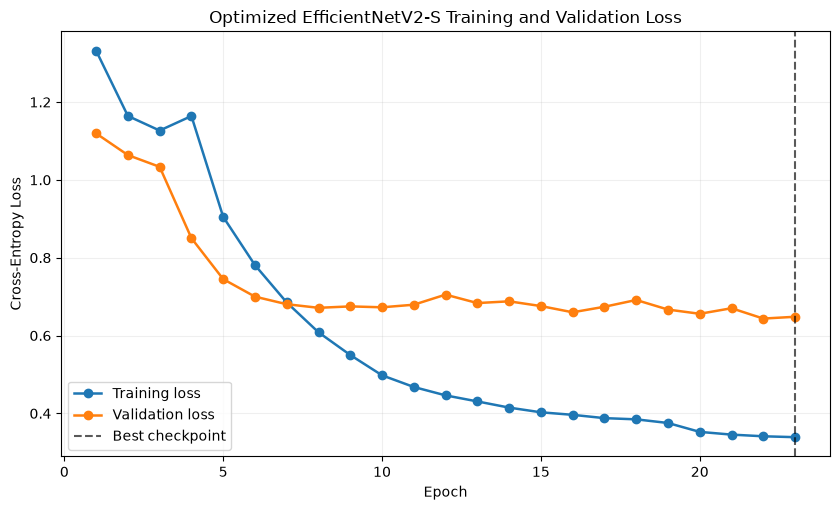

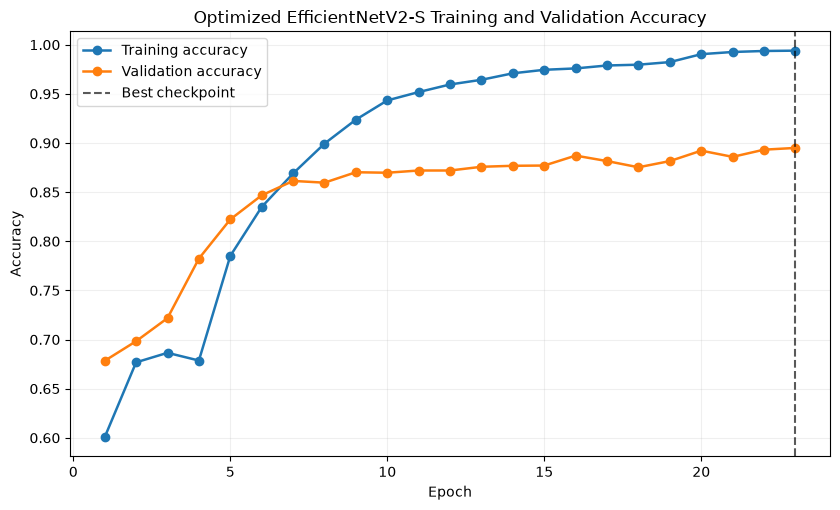

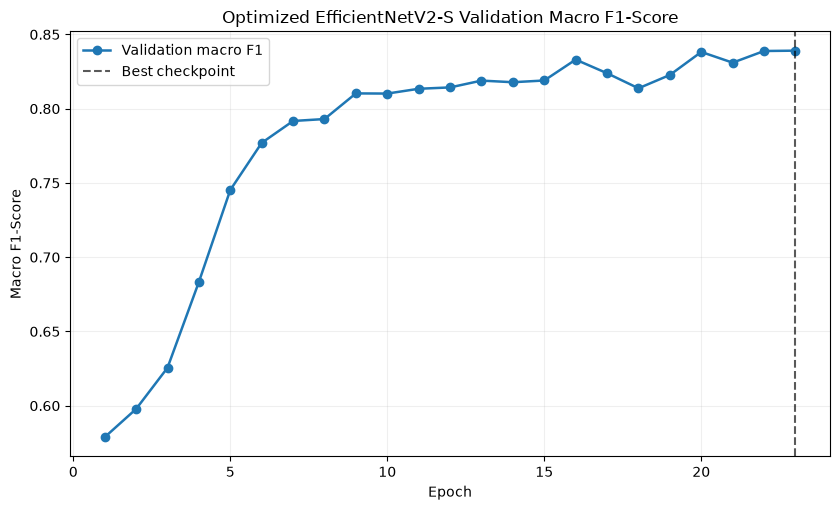

In [13]:
def save_curve(
    history_frame: pd.DataFrame,
    columns: list[str],
    labels: list[str],
    ylabel: str,
    title: str,
    output_path: Path,
) -> None:
    """Plot selected history columns and mark the checkpoint epoch."""
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    for column, label in zip(columns, labels):
        ax.plot(
            history_frame["epoch"],
            history_frame[column],
            marker="o",
            linewidth=1.8,
            label=label,
        )
    ax.axvline(
        best_epoch,
        color="black",
        linestyle="--",
        alpha=0.65,
        label="Best checkpoint",
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.20)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


save_curve(
    training_history,
    ["train_loss", "val_loss"],
    ["Training loss", "Validation loss"],
    "Cross-Entropy Loss",
    "Optimized EfficientNetV2-S Training and Validation Loss",
    FIGURES_DIR / "07_efficientnetv2_optimized_loss_curve.png",
)
save_curve(
    training_history,
    ["train_accuracy", "val_accuracy"],
    ["Training accuracy", "Validation accuracy"],
    "Accuracy",
    "Optimized EfficientNetV2-S Training and Validation Accuracy",
    FIGURES_DIR / "07_efficientnetv2_optimized_accuracy_curve.png",
)
save_curve(
    training_history,
    ["val_macro_f1"],
    ["Validation macro F1"],
    "Macro F1-Score",
    "Optimized EfficientNetV2-S Validation Macro F1-Score",
    FIGURES_DIR / "07_efficientnetv2_optimized_macro_f1_curve.png",
)


## 14. Best Optimized Checkpoint and Validation Metrics

The selected optimized checkpoint is reloaded before every subsequent analysis. Aggregate and per-class results retain the schemas used by the architecture baselines.


In [14]:
checkpoint = load_model_checkpoint(CHECKPOINT_PATH, model, DEVICE)

if checkpoint["class_mapping"] != CLASS_ID_TO_NAME:
    raise ValueError(
        "The checkpoint class mapping differs from the active manifest mapping."
    )
if checkpoint["architecture"] != "EfficientNetV2-S Optimized":
    raise ValueError("The checkpoint architecture metadata is inconsistent.")
if checkpoint["image_size"] != IMAGE_SIZE:
    raise ValueError("The checkpoint image size differs from the active pipeline.")

best_validation = evaluate_model(
    model,
    validation_loader,
    criterion,
    DEVICE,
    description="Best-checkpoint validation",
)
expected_validation_paths = manifests["validation"]["relative_path"].tolist()
if best_validation["relative_paths"] != expected_validation_paths:
    raise ValueError("Validation prediction order differs from the manifest order.")

validation_targets = best_validation["targets"]
validation_predictions = best_validation["predictions"]
validation_metric_values = {
    "accuracy": accuracy_score(validation_targets, validation_predictions),
    "balanced_accuracy": balanced_accuracy_score(
        validation_targets, validation_predictions
    ),
    "macro_f1": f1_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_precision": precision_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_recall": recall_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        validation_targets,
        validation_predictions,
        average="weighted",
        zero_division=0,
    ),
}
validation_metrics_table = pd.DataFrame(
    {
        "metric": list(validation_metric_values),
        "value": list(validation_metric_values.values()),
    }
)
validation_metrics_table.to_csv(
    REPORTS_DIR / "07_efficientnetv2_optimized_validation_metrics.csv",
    index=False,
    encoding="utf-8",
)

class_ids = class_mapping_table["class_id"].to_numpy()
per_class_precision, per_class_recall, per_class_f1, per_class_support = (
    precision_recall_fscore_support(
        validation_targets,
        validation_predictions,
        labels=class_ids,
        zero_division=0,
    )
)
per_class_metrics = pd.DataFrame(
    {
        "class_id": class_ids,
        "class_name": [
            CLASS_ID_TO_NAME[int(class_id)] for class_id in class_ids
        ],
        "precision": per_class_precision,
        "recall": per_class_recall,
        "f1_score": per_class_f1,
        "support": per_class_support.astype(int),
    }
)
per_class_metrics.to_csv(
    REPORTS_DIR / "07_efficientnetv2_optimized_per_class_metrics.csv",
    index=False,
    encoding="utf-8",
)

print(
    f"Loaded best checkpoint from epoch {checkpoint['epoch']} "
    f"({checkpoint['stage']})."
)
display(validation_metrics_table.style.format({"value": "{:.4f}"}))
display(
    per_class_metrics.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
            "support": "{:,}",
        }
    )
)


Best-checkpoint validation:   0%|          | 0/496 [00:00<?, ?batch/s]

Loaded best checkpoint from epoch 23 (full_fine_tuning).


,metric,value
0,accuracy,0.8950
1,balanced_accuracy,0.8394
2,macro_f1,0.8391
3,macro_precision,0.8399
4,macro_recall,0.8394
5,weighted_f1,0.8951


,class_id,class_name,precision,recall,f1_score,support
0,0,Eczema,0.7178,0.7588,0.7377,228
1,1,Melanoma,0.9937,1.0000,0.9968,471
2,2,Atopic Dermatitis,0.6171,0.6316,0.6243,171
3,3,Basal Cell Carcinoma (BCC),0.9696,0.9638,0.9667,497
4,4,Melanocytic Nevi (NV),0.9808,0.9858,0.9833,"1,195"
5,5,Benign Keratosis-like Lesions (BKL),0.9115,0.8968,0.9041,310
6,6,Psoriasis / Lichen Planus / Related Diseases,0.8015,0.7192,0.7581,292
7,7,Seborrheic Keratoses / Other Benign Tumors,0.8750,0.8205,0.8469,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.7323,0.8041,0.7665,245
9,9,Warts / Molluscum / Other Viral Infections,0.7993,0.8136,0.8064,279


## 15. Validation Predictions and Confidence

Hard predictions, maximum softmax confidence, and one probability column per class are saved for the best optimized checkpoint. These values support later final analysis and retrospective disagreement studies. Softmax confidence is not treated as a calibrated clinical probability.


Average confidence for correct predictions: 0.9245
Average confidence for incorrect predictions: 0.7430
Saved validation predictions: C:\Projekt konferencyjny Turcja\skin-disease-classification\reports\predictions\07_efficientnetv2_optimized_validation_predictions.csv


,example_type,relative_path,true_class,predicted_class,confidence
0,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections - 2103/6_278.jpg,Warts / Molluscum / Other Viral Infections,Warts / Molluscum / Other Viral Infections,1.0000
1,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/t-05atopicDerm040405ok1.jpg,Atopic Dermatitis,Atopic Dermatitis,0.9872
2,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/8. Seborrheic Keratoses and other Benign Tumors - 1.8k/t-epidermal-nevus-46.jpg,Seborrheic Keratoses / Other Benign Tumors,Seborrheic Keratoses / Other Benign Tumors,0.9848
3,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/8. Seborrheic Keratoses and other Benign Tumors - 1.8k/v-seborrheic-keratoses-smooth-114.jpg,Seborrheic Keratoses / Other Benign Tumors,Seborrheic Keratoses / Other Benign Tumors,0.9837
4,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/7. Psoriasis pictures Lichen Planus and related diseases - 2k/0_11.jpg,Psoriasis / Lichen Planus / Related Diseases,Atopic Dermatitis,0.9768
5,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections - 2103/0_25.jpg,Warts / Molluscum / Other Viral Infections,Atopic Dermatitis,0.9758
6,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/7. Psoriasis pictures Lichen Planus and related diseases - 2k/t-psoriasis-digits-4.jpg,Psoriasis / Lichen Planus / Related Diseases,Eczema,0.9681
7,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/v-lichen-simplex-chronicus-160.jpg,Eczema,Atopic Dermatitis,0.9661


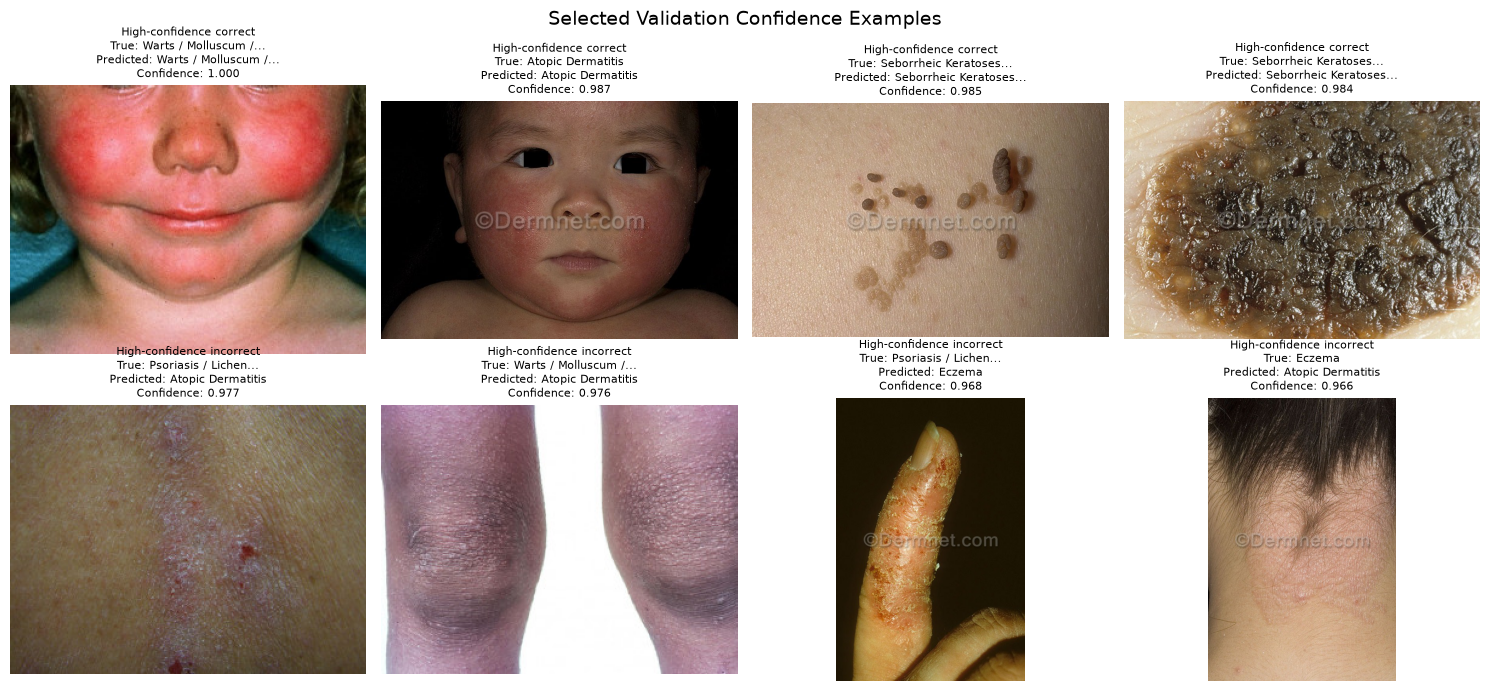

In [15]:
validation_predictions_table = pd.DataFrame(
    {
        "relative_path": best_validation["relative_paths"],
        "true_class_id": validation_targets,
        "true_class": [
            CLASS_ID_TO_NAME[int(class_id)] for class_id in validation_targets
        ],
        "predicted_class_id": validation_predictions,
        "predicted_class": [
            CLASS_ID_TO_NAME[int(class_id)]
            for class_id in validation_predictions
        ],
        "confidence": best_validation["confidences"],
        "correct": validation_targets == validation_predictions,
    }
)
for probability_index, class_id in enumerate(class_ids):
    validation_predictions_table[f"prob_class_{int(class_id)}"] = (
        best_validation["probabilities"][:, probability_index]
    )

PREDICTIONS_PATH = (
    PREDICTIONS_DIR / "07_efficientnetv2_optimized_validation_predictions.csv"
)
validation_predictions_table.to_csv(
    PREDICTIONS_PATH, index=False, encoding="utf-8"
)

correct_confidence = validation_predictions_table.loc[
    validation_predictions_table["correct"], "confidence"
].mean()
incorrect_confidence = validation_predictions_table.loc[
    ~validation_predictions_table["correct"], "confidence"
].mean()

print(f"Average confidence for correct predictions: {correct_confidence:.4f}")
print(f"Average confidence for incorrect predictions: {incorrect_confidence:.4f}")
print(f"Saved validation predictions: {PREDICTIONS_PATH}")

confidence_examples = pd.concat(
    [
        validation_predictions_table.loc[
            validation_predictions_table["correct"]
        ]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence correct"),
        validation_predictions_table.loc[
            ~validation_predictions_table["correct"]
        ]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence incorrect"),
    ],
    ignore_index=True,
)
display(
    confidence_examples[
        [
            "example_type",
            "relative_path",
            "true_class",
            "predicted_class",
            "confidence",
        ]
    ].style.format({"confidence": "{:.4f}"})
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7), squeeze=False)
for axis, (_, row) in zip(axes.flat, confidence_examples.iterrows()):
    with Image.open(PROJECT_ROOT / row["relative_path"]) as image:
        image_for_display = ImageOps.exif_transpose(image).convert("RGB")
        axis.imshow(image_for_display)
    axis.set_title(
        f"{row['example_type']}\n"
        f"True: {textwrap.shorten(row['true_class'], 24, placeholder='...')}\n"
        f"Predicted: "
        f"{textwrap.shorten(row['predicted_class'], 24, placeholder='...')}\n"
        f"Confidence: {row['confidence']:.3f}",
        fontsize=8,
    )
    axis.axis("off")
for axis in axes.flat[len(confidence_examples):]:
    axis.axis("off")
fig.suptitle("Selected Validation Confidence Examples", fontsize=14)
fig.tight_layout()
plt.show()


## 16. Confusion Matrices

The raw matrix reports validation image counts. Row normalization reports the prediction distribution within each true class.


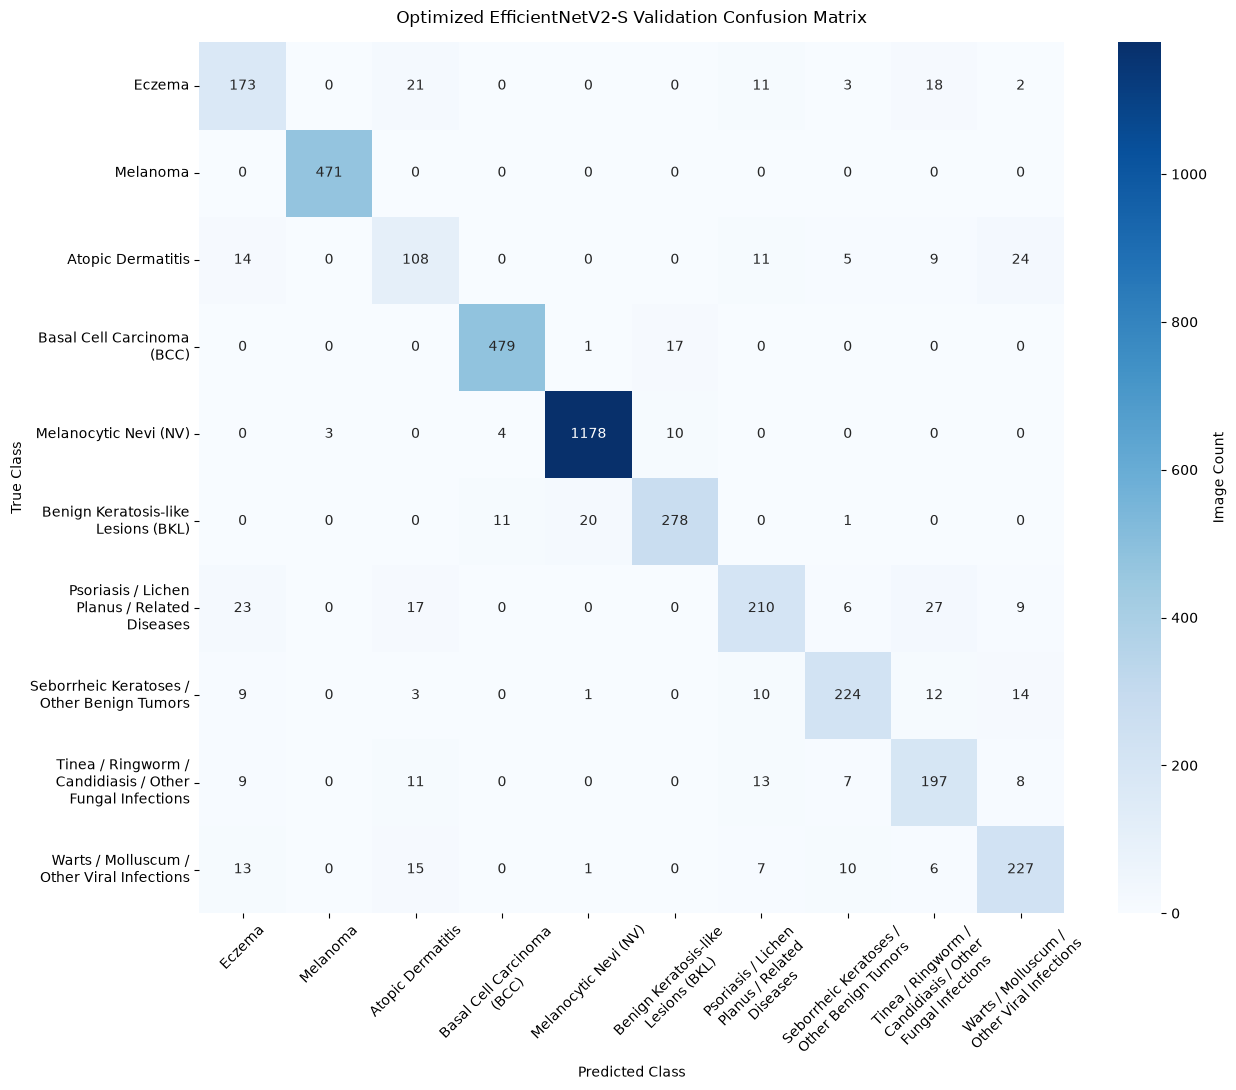

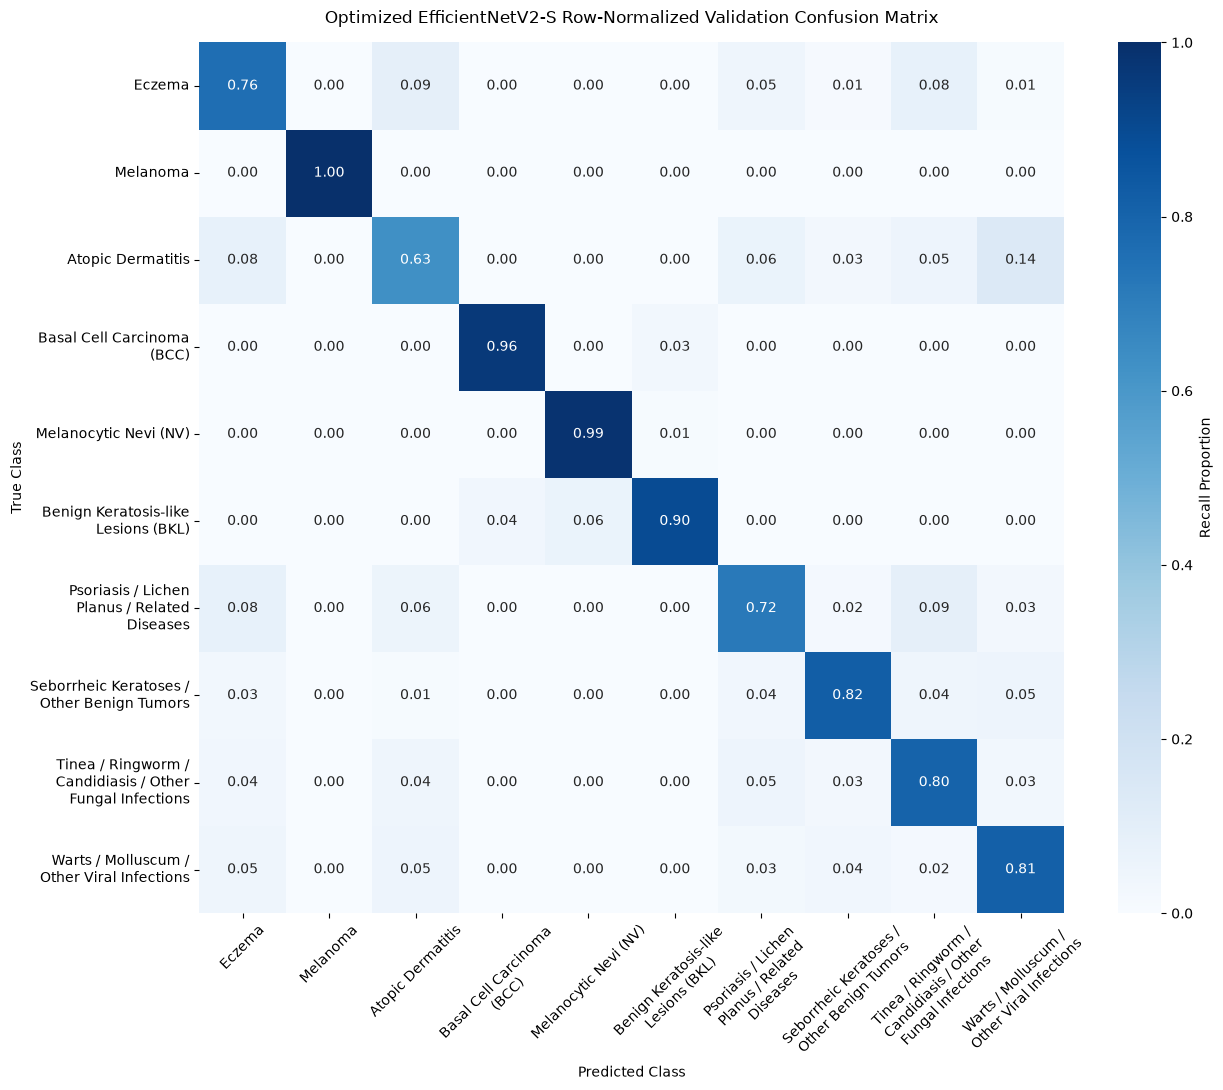

In [16]:
raw_confusion_matrix = confusion_matrix(
    validation_targets, validation_predictions, labels=class_ids
)
normalized_confusion_matrix = confusion_matrix(
    validation_targets,
    validation_predictions,
    labels=class_ids,
    normalize="true",
)
display_labels = [
    textwrap.fill(CLASS_ID_TO_NAME[int(class_id)], width=24)
    for class_id in class_ids
]


def plot_confusion_matrix(
    matrix,
    title: str,
    output_path: Path,
    value_format: str,
    colorbar_label: str,
) -> None:
    """Save a labeled validation confusion matrix."""
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=value_format,
        cmap="Blues",
        xticklabels=display_labels,
        yticklabels=display_labels,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )
    ax.set_title(title, pad=14)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    raw_confusion_matrix,
    "Optimized EfficientNetV2-S Validation Confusion Matrix",
    FIGURES_DIR / "07_efficientnetv2_optimized_confusion_matrix.png",
    "d",
    "Image Count",
)
plot_confusion_matrix(
    normalized_confusion_matrix,
    "Optimized EfficientNetV2-S Row-Normalized Validation Confusion Matrix",
    FIGURES_DIR / "07_efficientnetv2_optimized_confusion_matrix_normalized.png",
    ".2f",
    "Recall Proportion",
)


## 17. Optimized-Model Error Analysis

Class-level extrema and directed confusion counts are reported without unsupported medical explanations. Comparison with the baseline focuses on saved per-class metrics because notebook 04 did not preserve a machine-readable baseline prediction table.


In [17]:
highest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmax()]
lowest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmin()]
highest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmax()]
lowest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmin()]

off_diagonal_confusions = raw_confusion_matrix.copy()
np.fill_diagonal(off_diagonal_confusions, 0)
confusion_records = []
for true_index, predicted_index in zip(
    *np.where(off_diagonal_confusions > 0)
):
    confusion_records.append(
        {
            "true_class": CLASS_ID_TO_NAME[int(class_ids[true_index])],
            "predicted_class": CLASS_ID_TO_NAME[
                int(class_ids[predicted_index])
            ],
            "image_count": int(
                off_diagonal_confusions[true_index, predicted_index]
            ),
        }
    )
frequent_confusions = pd.DataFrame(
    confusion_records,
    columns=["true_class", "predicted_class", "image_count"],
).sort_values(
    ["image_count", "true_class", "predicted_class"],
    ascending=[False, True, True],
    ignore_index=True,
)
if frequent_confusions.empty:
    most_common_confusion = {
        "true_class": "none",
        "predicted_class": "none",
        "image_count": 0,
    }
else:
    most_common_confusion = frequent_confusions.iloc[0]

print(
    f"Highest validation recall: {highest_recall_row['class_name']} "
    f"({highest_recall_row['recall']:.4f})"
)
print(
    f"Lowest validation recall: {lowest_recall_row['class_name']} "
    f"({lowest_recall_row['recall']:.4f})"
)
print(
    f"Highest validation F1: {highest_f1_row['class_name']} "
    f"({highest_f1_row['f1_score']:.4f})"
)
print(
    f"Lowest validation F1: {lowest_f1_row['class_name']} "
    f"({lowest_f1_row['f1_score']:.4f})"
)
print("Most frequent directed confusion pairs:")
display(frequent_confusions.head(10))


Highest validation recall: Melanoma (1.0000)
Lowest validation recall: Atopic Dermatitis (0.6316)
Highest validation F1: Melanoma (0.9968)
Lowest validation F1: Atopic Dermatitis (0.6243)
Most frequent directed confusion pairs:


,true_class,predicted_class,image_count
0,Psoriasis / Lichen Planus / Related Diseases,Tinea / Ringworm / Candidiasis / Other Fungal ...,27
1,Atopic Dermatitis,Warts / Molluscum / Other Viral Infections,24
2,Psoriasis / Lichen Planus / Related Diseases,Eczema,23
3,Eczema,Atopic Dermatitis,21
4,Benign Keratosis-like Lesions (BKL),Melanocytic Nevi (NV),20
5,Eczema,Tinea / Ringworm / Candidiasis / Other Fungal ...,18
6,Basal Cell Carcinoma (BCC),Benign Keratosis-like Lesions (BKL),17
7,Psoriasis / Lichen Planus / Related Diseases,Atopic Dermatitis,17
8,Warts / Molluscum / Other Viral Infections,Atopic Dermatitis,15
9,Atopic Dermatitis,Eczema,14


## 18. Baseline vs. Optimized Overall Metrics

The EfficientNetV2-S baseline and optimized validation reports are loaded from disk. Differences are calculated as optimized minus baseline for the same fixed validation split.


In [18]:
OPTIMIZED_METRICS_PATH = (
    REPORTS_DIR / "07_efficientnetv2_optimized_validation_metrics.csv"
)
COMPARISON_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "macro_precision",
    "macro_recall",
    "weighted_f1",
]


def load_metric_report(path: Path) -> pd.Series:
    """Load and validate a metric,value report."""
    report = pd.read_csv(path)
    if list(report.columns) != ["metric", "value"]:
        raise ValueError(f"Unexpected metric report schema in {path.name}.")
    if report["metric"].duplicated().any():
        raise ValueError(f"Duplicate metrics exist in {path.name}.")
    values = report.set_index("metric")["value"].astype(float)
    missing_metrics = [
        metric for metric in COMPARISON_METRICS if metric not in values.index
    ]
    if missing_metrics:
        raise ValueError(f"{path.name} is missing metrics: {missing_metrics}")
    return values


baseline_metric_values = load_metric_report(BASELINE_METRICS_PATH)
optimized_metric_values = load_metric_report(OPTIMIZED_METRICS_PATH)
baseline_vs_optimized = pd.DataFrame(
    {
        "metric": COMPARISON_METRICS,
        "baseline": [
            baseline_metric_values[metric] for metric in COMPARISON_METRICS
        ],
        "optimized": [
            optimized_metric_values[metric] for metric in COMPARISON_METRICS
        ],
    }
)
baseline_vs_optimized["absolute_difference"] = (
    baseline_vs_optimized["optimized"] - baseline_vs_optimized["baseline"]
)
baseline_vs_optimized.to_csv(
    REPORTS_DIR / "07_efficientnetv2_baseline_vs_optimized.csv",
    index=False,
    encoding="utf-8",
)
display(
    baseline_vs_optimized.style.format(
        {
            "baseline": "{:.4f}",
            "optimized": "{:.4f}",
            "absolute_difference": "{:+.4f}",
        }
    )
)

BASELINE_PREDICTIONS_PATH = (
    PREDICTIONS_DIR / "04_efficientnetv2_validation_predictions.csv"
)
baseline_confidence_available = BASELINE_PREDICTIONS_PATH.is_file()
baseline_correct_confidence = np.nan
baseline_incorrect_confidence = np.nan
if baseline_confidence_available:
    baseline_prediction_table = pd.read_csv(BASELINE_PREDICTIONS_PATH)
    required_confidence_columns = {"confidence", "correct"}
    missing_columns = required_confidence_columns - set(
        baseline_prediction_table.columns
    )
    if missing_columns:
        raise ValueError(
            "The baseline prediction file is missing columns: "
            f"{sorted(missing_columns)}"
        )
    if baseline_prediction_table["correct"].dtype != bool:
        converted_correct = (
            baseline_prediction_table["correct"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"true": True, "false": False})
        )
        if converted_correct.isna().any():
            raise ValueError("Could not parse baseline prediction correctness.")
        baseline_prediction_table["correct"] = converted_correct
    baseline_correct_confidence = baseline_prediction_table.loc[
        baseline_prediction_table["correct"], "confidence"
    ].mean()
    baseline_incorrect_confidence = baseline_prediction_table.loc[
        ~baseline_prediction_table["correct"], "confidence"
    ].mean()
    confidence_comparison = pd.DataFrame(
        {
            "prediction_group": ["Correct", "Incorrect"],
            "baseline_average_confidence": [
                baseline_correct_confidence,
                baseline_incorrect_confidence,
            ],
            "optimized_average_confidence": [
                correct_confidence,
                incorrect_confidence,
            ],
        }
    )
    display(confidence_comparison.style.format(precision=4))
else:
    print(
        "Baseline confidence comparison unavailable: notebook 04 did not save "
        "a validation prediction table. Baseline inference is not repeated here."
    )


,metric,baseline,optimized,absolute_difference
0,accuracy,0.8892,0.8950,+0.0058
1,balanced_accuracy,0.8327,0.8394,+0.0067
2,macro_f1,0.8319,0.8391,+0.0072
3,macro_precision,0.8349,0.8399,+0.0050
4,macro_recall,0.8327,0.8394,+0.0067
5,weighted_f1,0.8902,0.8951,+0.0049


Baseline confidence comparison unavailable: notebook 04 did not save a validation prediction table. Baseline inference is not repeated here.


## 19. Per-Class Baseline vs. Optimized Comparison

Precision, recall, and F1 are joined by class identifier and name. The analysis reports all class-level changes and separately inspects the three weakest baseline classes. Small differences are retained numerically but are not treated as proof of a meaningful effect.


In [19]:
OPTIMIZED_PER_CLASS_PATH = (
    REPORTS_DIR / "07_efficientnetv2_optimized_per_class_metrics.csv"
)
EXPECTED_PER_CLASS_COLUMNS = {
    "class_id",
    "class_name",
    "precision",
    "recall",
    "f1_score",
    "support",
}


def load_per_class_report(path: Path) -> pd.DataFrame:
    report = pd.read_csv(path)
    if set(report.columns) != EXPECTED_PER_CLASS_COLUMNS:
        raise ValueError(f"Unexpected per-class schema in {path.name}.")
    if report[["class_id", "class_name"]].duplicated().any():
        raise ValueError(f"Duplicate class rows exist in {path.name}.")
    return report


baseline_per_class = load_per_class_report(BASELINE_PER_CLASS_PATH)
optimized_per_class = load_per_class_report(OPTIMIZED_PER_CLASS_PATH)
per_class_comparison_full = baseline_per_class.merge(
    optimized_per_class,
    on=["class_id", "class_name"],
    how="inner",
    suffixes=("_baseline", "_optimized"),
    validate="one_to_one",
)
if len(per_class_comparison_full) != NUM_CLASSES:
    raise ValueError("Per-class reports do not share the complete class mapping.")
if not per_class_comparison_full["support_baseline"].equals(
    per_class_comparison_full["support_optimized"]
):
    raise ValueError("Validation support differs between baseline and optimized reports.")

per_class_comparison = pd.DataFrame(
    {
        "class_id": per_class_comparison_full["class_id"],
        "class_name": per_class_comparison_full["class_name"],
        "baseline_precision": per_class_comparison_full["precision_baseline"],
        "optimized_precision": per_class_comparison_full["precision_optimized"],
        "baseline_recall": per_class_comparison_full["recall_baseline"],
        "optimized_recall": per_class_comparison_full["recall_optimized"],
        "baseline_f1": per_class_comparison_full["f1_score_baseline"],
        "optimized_f1": per_class_comparison_full["f1_score_optimized"],
        "support": per_class_comparison_full["support_baseline"].astype(int),
    }
)
per_class_comparison.insert(
    4,
    "precision_difference",
    per_class_comparison["optimized_precision"]
    - per_class_comparison["baseline_precision"],
)
per_class_comparison.insert(
    7,
    "recall_difference",
    per_class_comparison["optimized_recall"]
    - per_class_comparison["baseline_recall"],
)
per_class_comparison.insert(
    10,
    "f1_difference",
    per_class_comparison["optimized_f1"]
    - per_class_comparison["baseline_f1"],
)
per_class_comparison.to_csv(
    REPORTS_DIR / "07_efficientnetv2_baseline_vs_optimized_per_class.csv",
    index=False,
    encoding="utf-8",
)

classes_improved = int((per_class_comparison["f1_difference"] > 0).sum())
classes_worsened = int((per_class_comparison["f1_difference"] < 0).sum())
classes_unchanged = int((per_class_comparison["f1_difference"] == 0).sum())
largest_improvement_row = per_class_comparison.loc[
    per_class_comparison["f1_difference"].idxmax()
]
largest_decrease_row = per_class_comparison.loc[
    per_class_comparison["f1_difference"].idxmin()
]
weakest_optimized_row = per_class_comparison.loc[
    per_class_comparison["optimized_f1"].idxmin()
]
weakest_baseline_classes = per_class_comparison.nsmallest(3, "baseline_f1").copy()
weakest_baseline_classes_improved = int(
    (weakest_baseline_classes["f1_difference"] > 0).sum()
)

baseline_f1_range = (
    per_class_comparison["baseline_f1"].max()
    - per_class_comparison["baseline_f1"].min()
)
optimized_f1_range = (
    per_class_comparison["optimized_f1"].max()
    - per_class_comparison["optimized_f1"].min()
)

display(
    per_class_comparison.style.format(
        {
            column: "{:.4f}"
            for column in per_class_comparison.columns
            if column not in {"class_id", "class_name", "support"}
        }
    )
)
print(f"Classes with improved F1: {classes_improved}")
print(f"Classes with lower F1: {classes_worsened}")
print(f"Classes with unchanged F1: {classes_unchanged}")
print(
    "Largest F1 improvement: "
    f"{largest_improvement_row['class_name']} "
    f"({largest_improvement_row['f1_difference']:+.4f})"
)
print(
    "Largest F1 decrease: "
    f"{largest_decrease_row['class_name']} "
    f"({largest_decrease_row['f1_difference']:+.4f})"
)
print(
    "Weakest optimized class: "
    f"{weakest_optimized_row['class_name']} "
    f"({weakest_optimized_row['optimized_f1']:.4f})"
)
print("Three weakest baseline classes:")
display(
    weakest_baseline_classes[
        ["class_name", "support", "baseline_f1", "optimized_f1", "f1_difference"]
    ].style.format(
        {
            "baseline_f1": "{:.4f}",
            "optimized_f1": "{:.4f}",
            "f1_difference": "{:+.4f}",
        }
    )
)


,class_id,class_name,baseline_precision,optimized_precision,precision_difference,baseline_recall,optimized_recall,recall_difference,baseline_f1,optimized_f1,f1_difference,support
0,0,Eczema,0.7381,0.7178,-0.0203,0.6798,0.7588,0.0789,0.7078,0.7377,0.0300,228
1,1,Melanoma,0.9936,0.9937,0.0000,0.9958,1.0000,0.0042,0.9947,0.9968,0.0021,471
2,2,Atopic Dermatitis,0.5365,0.6171,0.0807,0.7310,0.6316,-0.0994,0.6188,0.6243,0.0055,171
3,3,Basal Cell Carcinoma (BCC),0.9527,0.9696,0.0170,0.9718,0.9638,-0.0080,0.9622,0.9667,0.0045,497
4,4,Melanocytic Nevi (NV),0.9833,0.9808,-0.0025,0.9858,0.9858,0.0000,0.9845,0.9833,-0.0012,1195
5,5,Benign Keratosis-like Lesions (BKL),0.9189,0.9115,-0.0074,0.8774,0.8968,0.0194,0.8977,0.9041,0.0064,310
6,6,Psoriasis / Lichen Planus / Related Diseases,0.7431,0.8015,0.0585,0.7329,0.7192,-0.0137,0.7379,0.7581,0.0202,292
7,7,Seborrheic Keratoses / Other Benign Tumors,0.8615,0.8750,0.0135,0.8205,0.8205,0.0000,0.8405,0.8469,0.0064,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.8288,0.7323,-0.0965,0.7510,0.8041,0.0531,0.7880,0.7665,-0.0215,245
9,9,Warts / Molluscum / Other Viral Infections,0.7927,0.7993,0.0066,0.7814,0.8136,0.0323,0.7870,0.8064,0.0194,279


Classes with improved F1: 8
Classes with lower F1: 2
Classes with unchanged F1: 0
Largest F1 improvement: Eczema (+0.0300)
Largest F1 decrease: Tinea / Ringworm / Candidiasis / Other Fungal Infections (-0.0215)
Weakest optimized class: Atopic Dermatitis (0.6243)
Three weakest baseline classes:


,class_name,support,baseline_f1,optimized_f1,f1_difference
2,Atopic Dermatitis,171,0.6188,0.6243,+0.0055
0,Eczema,228,0.7078,0.7377,+0.0300
6,Psoriasis / Lichen Planus / Related Diseases,292,0.7379,0.7581,+0.0202


## 20. Overfitting and Validation-Loss Comparison

The training-validation accuracy gap is measured at each macro-F1-selected checkpoint. A difference within 0.005 is described as approximately preserved. Validation-loss trajectories are summarized within each experiment; their absolute magnitudes are not directly equivalent because the optimized loss includes class weights and label smoothing.


In [20]:
baseline_history = pd.read_csv(BASELINE_HISTORY_PATH)
optimized_history = pd.read_csv(HISTORY_PATH)
required_history_columns = {
    "epoch",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "val_macro_f1",
}
for history_name, history_frame in {
    "baseline": baseline_history,
    "optimized": optimized_history,
}.items():
    missing_columns = required_history_columns - set(history_frame.columns)
    if missing_columns:
        raise ValueError(
            f"The {history_name} history is missing columns: "
            f"{sorted(missing_columns)}"
        )

baseline_selected_history = baseline_history.loc[
    baseline_history["val_macro_f1"].idxmax()
]
optimized_selected_rows = optimized_history.loc[
    optimized_history["epoch"] == checkpoint["epoch"]
]
if len(optimized_selected_rows) != 1:
    raise ValueError("Optimized checkpoint epoch is not unique in its history.")
optimized_selected_history = optimized_selected_rows.iloc[0]

baseline_training_validation_gap = (
    float(baseline_selected_history["train_accuracy"])
    - float(baseline_metric_values["accuracy"])
)
optimized_training_validation_gap = (
    float(optimized_selected_history["train_accuracy"])
    - float(optimized_metric_values["accuracy"])
)
training_validation_gap = optimized_training_validation_gap
gap_difference = (
    optimized_training_validation_gap - baseline_training_validation_gap
)
GAP_PRESERVATION_TOLERANCE = 0.005
if gap_difference < -GAP_PRESERVATION_TOLERANCE:
    gap_outcome = "reduced"
elif gap_difference > GAP_PRESERVATION_TOLERANCE:
    gap_outcome = "increased"
else:
    gap_outcome = "approximately preserved"

generalization_gap_comparison = pd.DataFrame(
    {
        "model": ["EfficientNetV2-S Baseline", "EfficientNetV2-S Optimized"],
        "selected_epoch": [
            int(baseline_selected_history["epoch"]),
            int(optimized_selected_history["epoch"]),
        ],
        "training_accuracy": [
            float(baseline_selected_history["train_accuracy"]),
            float(optimized_selected_history["train_accuracy"]),
        ],
        "validation_accuracy": [
            float(baseline_metric_values["accuracy"]),
            float(optimized_metric_values["accuracy"]),
        ],
        "training_validation_accuracy_gap": [
            baseline_training_validation_gap,
            optimized_training_validation_gap,
        ],
    }
)
display(
    generalization_gap_comparison.style.format(
        {
            "training_accuracy": "{:.4f}",
            "validation_accuracy": "{:.4f}",
            "training_validation_accuracy_gap": "{:+.4f}",
        }
    )
)
print(
    f"The optimized recipe {gap_outcome} the accuracy gap; "
    f"optimized minus baseline gap = {gap_difference:+.4f}."
)

validation_loss_behavior = pd.DataFrame(
    [
        {
            "model": model_name,
            "minimum_validation_loss": history_frame["val_loss"].min(),
            "minimum_loss_epoch": int(
                history_frame.loc[history_frame["val_loss"].idxmin(), "epoch"]
            ),
            "selected_checkpoint_validation_loss": float(
                selected_row["val_loss"]
            ),
            "final_validation_loss": float(history_frame.iloc[-1]["val_loss"]),
        }
        for model_name, history_frame, selected_row in [
            (
                "EfficientNetV2-S Baseline",
                baseline_history,
                baseline_selected_history,
            ),
            (
                "EfficientNetV2-S Optimized",
                optimized_history,
                optimized_selected_history,
            ),
        ]
    ]
)
display(
    validation_loss_behavior.style.format(
        {
            "minimum_validation_loss": "{:.4f}",
            "selected_checkpoint_validation_loss": "{:.4f}",
            "final_validation_loss": "{:.4f}",
        }
    )
)


,model,selected_epoch,training_accuracy,validation_accuracy,training_validation_accuracy_gap
0,EfficientNetV2-S Baseline,20,0.9936,0.8892,+0.1044
1,EfficientNetV2-S Optimized,23,0.9939,0.8950,+0.0990


The optimized recipe reduced the accuracy gap; optimized minus baseline gap = -0.0055.


,model,minimum_validation_loss,minimum_loss_epoch,selected_checkpoint_validation_loss,final_validation_loss
0,EfficientNetV2-S Baseline,0.4240,6,0.5813,0.6114
1,EfficientNetV2-S Optimized,0.6436,22,0.6482,0.6482


## Final Model Candidate Selection

Selection compares the EfficientNetV2-S baseline with the single optimized run. Validation macro F1 is primary. If macro F1 is exactly tied, balanced accuracy and then accuracy act as secondary criteria. The optimized model is not selected automatically, and no test result contributes to this decision.


In [21]:
baseline_macro_f1 = float(baseline_metric_values["macro_f1"])
optimized_macro_f1 = float(optimized_metric_values["macro_f1"])

if optimized_macro_f1 > baseline_macro_f1:
    FINAL_CANDIDATE = "efficientnetv2_s_optimized"
    selection_reason = "higher validation macro F1"
elif optimized_macro_f1 < baseline_macro_f1:
    FINAL_CANDIDATE = "efficientnetv2_s_baseline"
    selection_reason = "the optimized model has lower validation macro F1"
elif (
    optimized_metric_values["balanced_accuracy"]
    > baseline_metric_values["balanced_accuracy"]
):
    FINAL_CANDIDATE = "efficientnetv2_s_optimized"
    selection_reason = "equal macro F1 and higher balanced accuracy"
elif (
    optimized_metric_values["balanced_accuracy"]
    < baseline_metric_values["balanced_accuracy"]
):
    FINAL_CANDIDATE = "efficientnetv2_s_baseline"
    selection_reason = "equal macro F1 and higher baseline balanced accuracy"
elif optimized_metric_values["accuracy"] > baseline_metric_values["accuracy"]:
    FINAL_CANDIDATE = "efficientnetv2_s_optimized"
    selection_reason = "equal macro F1/balanced accuracy and higher accuracy"
else:
    FINAL_CANDIDATE = "efficientnetv2_s_baseline"
    selection_reason = "no validation advantage over the baseline"

final_candidate_selection = pd.DataFrame(
    {
        "candidate": [
            "efficientnetv2_s_baseline",
            "efficientnetv2_s_optimized",
        ],
        "validation_accuracy": [
            baseline_metric_values["accuracy"],
            optimized_metric_values["accuracy"],
        ],
        "validation_balanced_accuracy": [
            baseline_metric_values["balanced_accuracy"],
            optimized_metric_values["balanced_accuracy"],
        ],
        "validation_macro_f1": [
            baseline_metric_values["macro_f1"],
            optimized_metric_values["macro_f1"],
        ],
    }
)
final_candidate_selection["selected"] = (
    final_candidate_selection["candidate"] == FINAL_CANDIDATE
)
final_candidate_selection.to_csv(
    REPORTS_DIR / "07_final_candidate_selection.csv",
    index=False,
    encoding="utf-8",
)

selected_checkpoint_for_notebook_08 = (
    OPTIMIZED_CHECKPOINT_PATH
    if FINAL_CANDIDATE == "efficientnetv2_s_optimized"
    else BASELINE_CHECKPOINT_PATH
)
candidate_decision_metrics = pd.DataFrame(
    {
        "metric": [
            "Validation accuracy",
            "Validation balanced accuracy",
            "Validation macro F1",
            "Validation macro recall",
            "Training-validation accuracy gap",
        ],
        "baseline": [
            baseline_metric_values["accuracy"],
            baseline_metric_values["balanced_accuracy"],
            baseline_metric_values["macro_f1"],
            baseline_metric_values["macro_recall"],
            baseline_training_validation_gap,
        ],
        "optimized": [
            optimized_metric_values["accuracy"],
            optimized_metric_values["balanced_accuracy"],
            optimized_metric_values["macro_f1"],
            optimized_metric_values["macro_recall"],
            optimized_training_validation_gap,
        ],
    }
)
display(candidate_decision_metrics.style.format(precision=4))
display(final_candidate_selection.style.format(precision=4))
print(f"Selected final candidate: {FINAL_CANDIDATE}")
print(f"Selection reason: {selection_reason}")
print(
    "Checkpoint for notebook 08: "
    f"{selected_checkpoint_for_notebook_08.relative_to(PROJECT_ROOT).as_posix()}"
)


,metric,baseline,optimized
0,Validation accuracy,0.8892,0.8950
1,Validation balanced accuracy,0.8327,0.8394
2,Validation macro F1,0.8319,0.8391
3,Validation macro recall,0.8327,0.8394
4,Training-validation accuracy gap,0.1044,0.0990


,candidate,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,selected
0,efficientnetv2_s_baseline,0.8892,0.8327,0.8319,False
1,efficientnetv2_s_optimized,0.8950,0.8394,0.8391,True


Selected final candidate: efficientnetv2_s_optimized
Selection reason: higher validation macro F1
Checkpoint for notebook 08: models/efficientnetv2_s_optimized_best.pth


## 22. Baseline vs. Optimized Comparison Figures

These figures are intermediate experiment-analysis outputs rather than a final poster layout. They may be reused or redesigned after the frozen test evaluation.


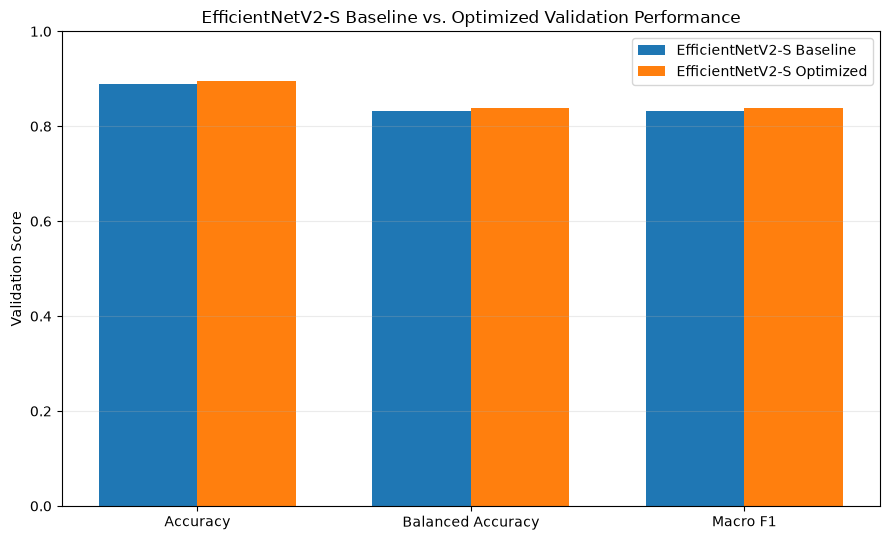

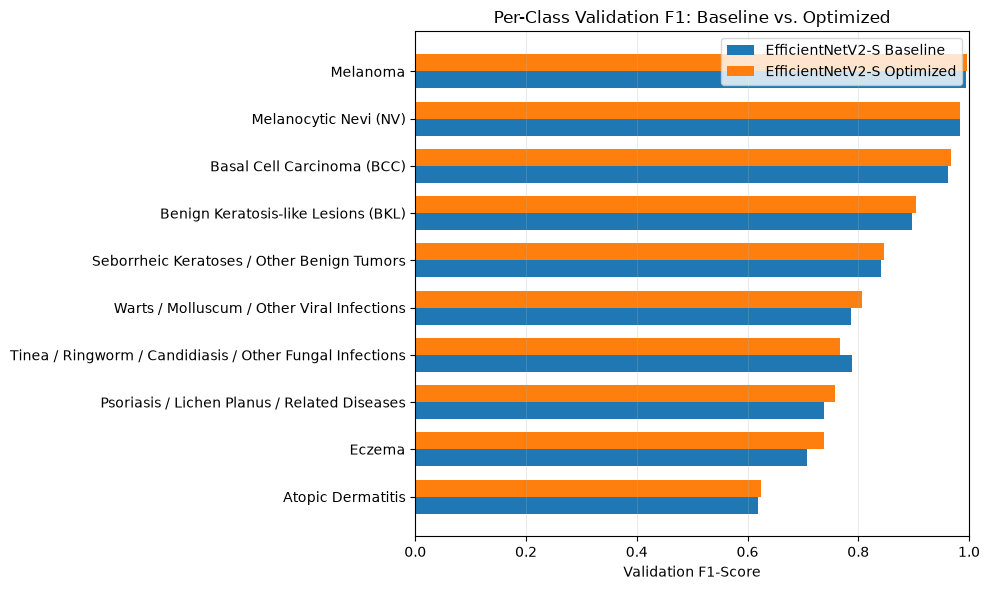

In [22]:
main_metric_names = ["accuracy", "balanced_accuracy", "macro_f1"]
main_metric_labels = ["Accuracy", "Balanced Accuracy", "Macro F1"]
main_comparison = baseline_vs_optimized.set_index("metric").loc[
    main_metric_names
]
x_positions = np.arange(len(main_metric_names))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(
    x_positions - bar_width / 2,
    main_comparison["baseline"],
    width=bar_width,
    label="EfficientNetV2-S Baseline",
)
ax.bar(
    x_positions + bar_width / 2,
    main_comparison["optimized"],
    width=bar_width,
    label="EfficientNetV2-S Optimized",
)
ax.set_xticks(x_positions, main_metric_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Validation Score")
ax.set_title("EfficientNetV2-S Baseline vs. Optimized Validation Performance")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "07_efficientnetv2_baseline_vs_optimized.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

per_class_plot = per_class_comparison.sort_values(
    "optimized_f1", ascending=True
).reset_index(drop=True)
y_positions = np.arange(len(per_class_plot))
fig, ax = plt.subplots(figsize=(10, max(6, 0.50 * len(per_class_plot))))
ax.barh(
    y_positions - bar_width / 2,
    per_class_plot["baseline_f1"],
    height=bar_width,
    label="EfficientNetV2-S Baseline",
)
ax.barh(
    y_positions + bar_width / 2,
    per_class_plot["optimized_f1"],
    height=bar_width,
    label="EfficientNetV2-S Optimized",
)
ax.set_yticks(y_positions, per_class_plot["class_name"])
ax.set_xlim(0, 1)
ax.set_xlabel("Validation F1-Score")
ax.set_title("Per-Class Validation F1: Baseline vs. Optimized")
ax.legend()
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR
    / "07_efficientnetv2_baseline_vs_optimized_per_class_f1.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## Final Optimization Summary

The summary below is generated from the selected optimized checkpoint and the saved baseline comparison.


In [23]:
macro_f1_difference = optimized_macro_f1 - baseline_macro_f1
accuracy_difference = (
    optimized_metric_values["accuracy"] - baseline_metric_values["accuracy"]
)
most_common_confusion_text = (
    f"true {most_common_confusion['true_class']} predicted as "
    f"{most_common_confusion['predicted_class']} "
    f"({int(most_common_confusion['image_count'])} images)"
)
final_summary_markdown = f"""
- **Best optimized epoch:** {checkpoint['epoch']} ({checkpoint['stage'].replace('_', ' ')})
- **Optimized validation accuracy:** {optimized_metric_values['accuracy']:.4f}
- **Optimized validation balanced accuracy:** {optimized_metric_values['balanced_accuracy']:.4f}
- **Optimized validation macro F1:** {optimized_metric_values['macro_f1']:.4f}
- **Optimized validation macro precision:** {optimized_metric_values['macro_precision']:.4f}
- **Optimized validation macro recall:** {optimized_metric_values['macro_recall']:.4f}
- **Strongest optimized class by F1:** {highest_f1_row['class_name']} ({highest_f1_row['f1_score']:.4f})
- **Weakest optimized class by F1:** {lowest_f1_row['class_name']} ({lowest_f1_row['f1_score']:.4f})
- **Most frequent optimized directed confusion:** {most_common_confusion_text}
- **Optimized training-validation accuracy gap:** {optimized_training_validation_gap:+.4f}
- **Baseline macro F1:** {baseline_macro_f1:.4f}
- **Optimized macro F1:** {optimized_macro_f1:.4f}
- **Macro F1 difference:** {macro_f1_difference:+.4f}
- **Baseline accuracy:** {baseline_metric_values['accuracy']:.4f}
- **Optimized accuracy:** {optimized_metric_values['accuracy']:.4f}
- **Accuracy difference:** {accuracy_difference:+.4f}
- **Classes improved in F1:** {classes_improved} of {NUM_CLASSES}
- **Selected final candidate:** {FINAL_CANDIDATE}
"""
display(Markdown(final_summary_markdown))



- **Best optimized epoch:** 23 (full fine tuning)
- **Optimized validation accuracy:** 0.8950
- **Optimized validation balanced accuracy:** 0.8394
- **Optimized validation macro F1:** 0.8391
- **Optimized validation macro precision:** 0.8399
- **Optimized validation macro recall:** 0.8394
- **Strongest optimized class by F1:** Melanoma (0.9968)
- **Weakest optimized class by F1:** Atopic Dermatitis (0.6243)
- **Most frequent optimized directed confusion:** true Psoriasis / Lichen Planus / Related Diseases predicted as Tinea / Ringworm / Candidiasis / Other Fungal Infections (27 images)
- **Optimized training-validation accuracy gap:** +0.0990
- **Baseline macro F1:** 0.8319
- **Optimized macro F1:** 0.8391
- **Macro F1 difference:** +0.0072
- **Baseline accuracy:** 0.8892
- **Optimized accuracy:** 0.8950
- **Accuracy difference:** +0.0058
- **Classes improved in F1:** 8 of 10
- **Selected final candidate:** efficientnetv2_s_optimized


### Interpretation

The combined recipe changes several factors simultaneously. Observed differences therefore describe the recipe as a whole and cannot be attributed causally to class weighting, label smoothing, dropout, augmentation, or learning rates in isolation.


In [24]:
if weakest_baseline_classes_improved == len(weakest_baseline_classes):
    weaker_class_text = (
        "All three weakest baseline classes improved in F1, which is consistent "
        "with the class-aware recipe benefiting weaker classes on this split."
    )
elif weakest_baseline_classes_improved > 0:
    weaker_class_text = (
        f"{weakest_baseline_classes_improved} of the three weakest baseline "
        "classes improved in F1; the benefit was not uniform across weaker classes."
    )
else:
    weaker_class_text = (
        "None of the three weakest baseline classes improved in F1, so this result "
        "does not support a weaker-class benefit from the combined recipe."
    )

if baseline_confidence_available:
    correct_confidence_change = correct_confidence - baseline_correct_confidence
    incorrect_confidence_change = (
        incorrect_confidence - baseline_incorrect_confidence
    )
    confidence_text = (
        "Relative to the baseline prediction table, average confidence changed by "
        f"{correct_confidence_change:+.4f} for correct predictions and "
        f"{incorrect_confidence_change:+.4f} for incorrect predictions. "
        "These changes do not establish calibration."
    )
else:
    confidence_text = (
        "The baseline experiment did not save validation confidences, so whether "
        "label smoothing reduced overconfidence cannot be tested directly without "
        "rerunning baseline inference."
    )

if accuracy_difference > 0:
    accuracy_text = f"Validation accuracy increased by {accuracy_difference:.4f}."
elif accuracy_difference < 0:
    accuracy_text = (
        f"Validation accuracy decreased by {abs(accuracy_difference):.4f}."
    )
else:
    accuracy_text = "Validation accuracy was unchanged."

f1_range_difference = optimized_f1_range - baseline_f1_range
if f1_range_difference < 0:
    balance_text = (
        f"The per-class F1 range narrowed by {abs(f1_range_difference):.4f}, "
        "indicating more even class-level performance on this validation split."
    )
elif f1_range_difference > 0:
    balance_text = (
        f"The per-class F1 range widened by {f1_range_difference:.4f}, indicating "
        "less even class-level performance on this validation split."
    )
else:
    balance_text = "The per-class F1 range was unchanged."

interpretation_markdown = f"""
{weaker_class_text} {confidence_text}

The optimized training-validation accuracy gap was {optimized_training_validation_gap:+.4f}, compared with {baseline_training_validation_gap:+.4f} for the baseline; the gap was **{gap_outcome}**. {accuracy_text} {balance_text}

Validation macro F1 changed by {macro_f1_difference:+.4f}. On the predefined selection rule, **{FINAL_CANDIDATE}** remains the preferred candidate for the single frozen-test evaluation.

Remaining limitations include heterogeneous image sources, DermNet watermarks, possible shortcut cues, the absence of universal patient-level identifiers, class imbalance, and validation-based model selection. Neither validation performance nor softmax confidence establishes external generalization, calibration, or clinical diagnostic reliability.
"""
display(Markdown(interpretation_markdown))



All three weakest baseline classes improved in F1, which is consistent with the class-aware recipe benefiting weaker classes on this split. The baseline experiment did not save validation confidences, so whether label smoothing reduced overconfidence cannot be tested directly without rerunning baseline inference.

The optimized training-validation accuracy gap was +0.0990, compared with +0.1044 for the baseline; the gap was **reduced**. Validation accuracy increased by 0.0058. The per-class F1 range narrowed by 0.0033, indicating more even class-level performance on this validation split.

Validation macro F1 changed by +0.0072. On the predefined selection rule, **efficientnetv2_s_optimized** remains the preferred candidate for the single frozen-test evaluation.

Remaining limitations include heterogeneous image sources, DermNet watermarks, possible shortcut cues, the absence of universal patient-level identifiers, class imbalance, and validation-based model selection. Neither validation performance nor softmax confidence establishes external generalization, calibration, or clinical diagnostic reliability.


## Test Set Policy

The test subset remains frozen until notebook 08. This notebook does not create test predictions, metrics, confidence values, confusion matrices, or error inspection.


In [25]:
TEST_SET_PREDICTIONS_GENERATED = False
print(f"Test-set predictions generated: {TEST_SET_PREDICTIONS_GENERATED}")


Test-set predictions generated: False


### Next Step

Model development is complete, and no further tuning is planned. Notebook 08 will load the checkpoint selected above and perform one final evaluation on the untouched test set. Test results must not be used for additional model tuning.

Subsequent work will report final test metrics, the test confusion matrix, per-class results, Grad-CAM or related interpretability analysis, and poster-ready figures.


## Reproducibility Summary

The table records the complete predefined optimization recipe and execution environment.


In [26]:
reproducibility_summary = pd.DataFrame(
    {
        "Configuration Item": [
            "Random seed",
            "Architecture",
            "Pretrained weights",
            "Image size",
            "Batch size",
            "Loss function",
            "Class weighting method",
            "Label smoothing",
            "Classifier dropout",
            "Optimizer",
            "Warm-up learning rate",
            "Backbone fine-tuning learning rate",
            "Classifier fine-tuning learning rate",
            "Weight decay",
            "Warm-up epochs",
            "Maximum fine-tuning epochs",
            "Early stopping patience",
            "Checkpoint criterion",
            "PyTorch version",
            "torchvision version",
            "CUDA version",
            "GPU name",
        ],
        "Value": [
            RANDOM_SEED,
            "EfficientNetV2-S Optimized",
            PRETRAINED_WEIGHTS.name,
            f"{IMAGE_SIZE} x {IMAGE_SIZE}",
            BATCH_SIZE,
            "Weighted CrossEntropyLoss with label smoothing",
            "Square-root inverse frequency, mean-normalized, clipped [0.75, 1.50]",
            LABEL_SMOOTHING,
            FINAL_DROPOUT,
            "AdamW",
            WARMUP_LEARNING_RATE,
            BACKBONE_LEARNING_RATE,
            CLASSIFIER_FINE_TUNE_LEARNING_RATE,
            WEIGHT_DECAY,
            WARMUP_EPOCHS,
            FINE_TUNE_MAX_EPOCHS,
            EARLY_STOPPING_PATIENCE,
            CHECKPOINT_CRITERION,
            torch.__version__,
            torchvision.__version__,
            torch.version.cuda,
            GPU_NAME,
        ],
    }
)
display(reproducibility_summary)
print(f"Completed epochs: {len(training_history)}")
print(
    "Optimized checkpoint path: "
    f"{OPTIMIZED_CHECKPOINT_PATH.relative_to(PROJECT_ROOT).as_posix()}"
)
print(f"Selected final candidate: {FINAL_CANDIDATE}")
print(
    "Selected checkpoint for notebook 08: "
    f"{selected_checkpoint_for_notebook_08.relative_to(PROJECT_ROOT).as_posix()}"
)
print("Test-set predictions generated: False")


,Configuration Item,Value
0,Random seed,42
1,Architecture,EfficientNetV2-S Optimized
2,Pretrained weights,IMAGENET1K_V1
3,Image size,384 x 384
4,Batch size,8
5,Loss function,Weighted CrossEntropyLoss with label smoothing
6,Class weighting method,"Square-root inverse frequency, mean-normalized..."
7,Label smoothing,0.05
8,Classifier dropout,0.3
9,Optimizer,AdamW


Completed epochs: 23
Optimized checkpoint path: models/efficientnetv2_s_optimized_best.pth
Selected final candidate: efficientnetv2_s_optimized
Selected checkpoint for notebook 08: models/efficientnetv2_s_optimized_best.pth
Test-set predictions generated: False
